# 从零实现 Transformer —— 完整讲义与代码 Notebook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/songyaolun/transformer-from-scratch/blob/main/transformer_from_scratch.ipynb)

本系列教程将带你从零开始，用 PyTorch 手写一个完整的 Transformer 模型，完成一个中英翻译任务。本 Notebook 已将 `docs/` 中的全部讲义正文、公式推导、图解、思考题与代码注释完整整合，可直接在此阅读与运行，无需来回翻阅文档。

> **在线阅读文章版**：[https://songyaolun.github.io/transformer-from-scratch/](https://songyaolun.github.io/transformer-from-scratch/)

## 写在前面

写这系列文章的灵感来自《[夏洛特烦恼](https://movie.douban.com/subject/25964071/)》和《[万物发明指南](https://book.douban.com/subject/34464674/)》——不管你穿越回过去的哪个时间点，总要有点真本事才能引领世界。我怕如果穿回去，只知道 AI 会来，却不知道它是怎么来的。当今世界 AI 巨变的基座就是 Transformer + 老黄的GPU，你提前把论文发出来，直接抢跑 Transformer 的发明权。

这个系列从今年 1 月就开始规划，过年期间到年后的几个周末写写停停，拖更了很久。我作为一个小白，有很多初级的困惑，想着可能会给其他初入门的同学一些参考。工作量确实不小——自己查资料、手写代码、顺整个流程，还有很多东西要重新学和查证。**本系列所有内容初版都是我一个字一个字敲出来的**，后经 AI 润色。你当然可以让 AI 直接生成一份教程，但可能没有这么多小白视角的旁白——把大家可能困惑的地方写出来，给出解释，应该算是独一份了。

我看了很多书和视频后，总结了一个公式：

$$文章信息质量 = \frac{创作者的（知识水平 \times 时间成本 \times 表达能力 \times 单位时间效率）}{知识理解门槛}$$

本系列的短板在于我个人的知识水平和表达能力；优点是投入了较多的时间成本，并且努力在降低理解门槛。写这个系列给我自己带来了很大的收获，也希望能给大家带来一些收获。

## 系列说明

本系列对应的所有代码都可从 https://github.com/songyaolun/transformer-from-scratch 下载到本地 Mac 运行，或直接使用 Colab 运行。当然我更建议大家自己手写一遍加深印象，手推一些模型参数输出。

笔者按内聚的学习内容将全系列分为 **5 个篇章**，推荐学习节奏是**五天工作日，每天一篇，每篇 30-60 分钟**，周末完成课后作业，刚好一周学完。学习步骤：

1. **阅读讲义**，回答文中穿插的小问题。有没有思路都可以点开答案看看，觉得答案写得不对欢迎交流。
2. **运行代码**，能自己手写一遍最好。现在大家用 AI 写代码，经常脑子跟不上 AI 的输出，手写虽然慢，但会给你思考的时间。对于一些 cell 的输出，试着手算一下为什么是这样。

## 全局架构总览

在开始之前，先看一张贯穿全系列的架构图，建立整体认知：

![Transformer 系列全局架构图](docs/images/transformer-architecture.png)

图中标注了五篇文章各自负责的模块，学习过程中可随时对照回来。

## 系列文章目录

| 序号 | 篇章 | 内容 |
|------|------|------|
| 01 | [第一篇：环境与前期准备](#part1) | 张量操作、nn.Module、常用层、训练流程 |
| 02 | [第二篇：数据处理与 Transformer 输入层](#part2) | 词表构建、Padding、Embedding、位置编码 |
| 03 | [第三篇：多头注意力机制与核心组件](#part3) | 注意力公式、FFN、残差连接、Encoder/Decoder Layer |
| 04 | [第四篇：Transformer 模型组装](#part4) | Mask、Encoder、Decoder、完整 Transformer |
| 05 | [第五篇：训练、推理与可视化](#part5) | 损失函数、训练循环、Greedy Decode、注意力可视化 |

## 环境要求

- Python 3.9+
- PyTorch 2.0+
- matplotlib, seaborn（可视化部分）

---
<a id='part1'></a>
# 动手学AI ⚡️ 手写Transformer 01：环境与前期准备

对应文章：[01-pytorch-basics.md](docs/01-pytorch-basics.md)

## 系列目录

1. **环境与前期准备**（本篇）
2. [数据处理与 Transformer 输入层](#part2)
3. [多头注意力机制与核心组件](#part3)
4. [模型组装](#part4)
5. [训练、推理与可视化](#part5)

---

## 1. 环境准备

因为很多小白会卡在开头，这部分就冗余了一些。了解这些概念的同学直接跳到第 2 节。

### 1.1 Colab

打开本系列关联的 Github 仓库：https://github.com/songyaolun/transformer-from-scratch，按以下步骤操作：

**第一步**，点击仓库中的 notebook 链接，在 Colab 中打开：

![Colab 打开步骤1](docs/images/01/1.png)

**第二步**，在跳转的新页面中选择右上角的小三角，选择**更改运行时类型**：

![Colab 更改运行时](docs/images/01/2.png)

**第三步**，选择 **T4 GPU** 并保存：

![选择 T4 GPU](docs/images/01/3.png)

**第四步**，点击**连接 T4**，稍等几秒：

![连接 T4](docs/images/01/4.png)

右上角出现 RAM 和磁盘，说明 Colab 已经连上了——给你分配了一台云端机器，有内存、有 GPU、有磁盘：

![RAM 和磁盘显示](docs/images/01/5.png)

**第五步**，将下图的内容取消注释并运行，即可安装后文所需的全部依赖：

![安装依赖](docs/images/01/6.png)

点击按钮开始运行代码：

![运行代码](docs/images/01/7.png)

In [4]:
# 在 Google Colab 中运行时，取消下面的注释来安装依赖
!uv pip install torch numpy matplotlib seaborn -q

### 1.2 PyCharm / VS Code

需要先在本地配置环境，推荐使用 Conda，安装好依赖后，第一次运行 Cell 时会询问你环境配置，指定到具体的配置就好。以 VS Code 举例：

点击 cell 左侧的 Run 按钮：

![VS Code 运行 Cell](docs/images/01/8.png)

弹出环境配置选项：

![选择环境](docs/images/01/9.png)

选择具体的环境（我用 Conda 专门建了一个）：

![选择 Conda 环境](docs/images/01/10.png)

然后运行第一段代码：

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.utils.data as data
import math
import numpy as np

# 自动检测可用硬件加速设备：Apple Silicon (mps) > NVIDIA GPU (cuda) > CPU
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"设备: {device}")

设备: mps


我的个人电脑是 M1 系列的 Mac，执行结果是 `设备: mps`。如果你用有 NVIDIA GPU 的电脑，或者使用 Colab 并选择了 Google 的免费 GPU，结果应该是 `设备: cuda`。

---

环境跑通了？下面正式开始。Transformer 的一切计算都建立在张量（Tensor）之上——你可以把它理解为多维数组的升级版。

---

## 2. 张量——AI 的积木

PyTorch 是当前深度学习的主流框架，类似于 Web 开发中的 React 或 Spring——帮你省掉重复劳动，专注核心逻辑。

### 2.1 创建张量

In [6]:
# 从列表创建一维张量
x = torch.tensor([1, 2, 3])
print(x)         # tensor([1, 2, 3])
print(x.shape)   # torch.Size([3])

# 从二维列表创建矩阵
matrix = torch.tensor([[1, 2], [3, 4]])
print(matrix)        # tensor([[1, 2], [3, 4]])
print(matrix.shape)  # torch.Size([2, 2])

# 从三维列表创建高维张量
matrix = torch.tensor([
    [
        [1, 2],
        [3, 4]
    ],
    [
        [1, 2],
        [3, 4]
    ]
])
print(matrix)
print(matrix.shape)  # torch.Size([2, 2, 2])

tensor([1, 2, 3])
torch.Size([3])
tensor([[1, 2],
        [3, 4]])
torch.Size([2, 2])
tensor([[[1, 2],
         [3, 4]],

        [[1, 2],
         [3, 4]]])
torch.Size([2, 2, 2])


常用的创建方法：

In [7]:
# 常用的张量创建方法：zeros, ones, randn
x = torch.zeros(2, 3)    # 全 0 张量
print(f"zeros: {x.shape}")

x = torch.ones(3, 2)     # 全 1 张量
print(f"ones: {x.shape}")

x = torch.randn(3, 4)    # 标准正态分布张量
print(f"randn: {x.shape}")

zeros: torch.Size([2, 3])
ones: torch.Size([3, 2])
randn: torch.Size([3, 4])


### 2.2 张量属性与索引

In [8]:
x = torch.randn(2, 4, 5)
print(f"shape: {x.shape}")   # torch.Size([2, 4, 5]) (形状)
print(f"dim: {x.dim()}")     # 3 (维度数)
print(f"numel: {x.numel()}") # 40 (元素总数 = 2 * 4 * 5)
print(f"dtype: {x.dtype}")   # torch.float32 (数据类型)

shape: torch.Size([2, 4, 5])
dim: 3
numel: 40
dtype: torch.float32


In [9]:
x = torch.tensor([[1, 2, 3], [4, 5, 6]])
print(f"x[0, 1] = {x[0, 1]}")   # 2 (访问第0行第1列的单个元素)
print(f"x[0] = {x[0]}")         # tensor([1, 2, 3]) (第一行)
print(f"x[:, 1:] = {x[:, 1:]}") # tensor([[2, 3], [5, 6]]) (所有行，从第1列到末尾切片)
print(f"x[:, :-1] = {x[:, :-1]}") # tensor([[1, 2], [4, 5]]) (所有行，去掉最后一列，后续 Teacher Forcing 会用到)

x[0, 1] = 2
x[0] = tensor([1, 2, 3])
x[:, 1:] = tensor([[2, 3],
        [5, 6]])
x[:, :-1] = tensor([[1, 2],
        [4, 5]])


### 2.3 形状操作

#### `view()` — 变换形状

In [10]:
# view: 变换形状（总元素个数保持不变）
x = torch.randn(2, 3, 4)
print(f"原始: {x.shape}")

x_flat = x.view(2, -1)             # (2, 12)，-1 表示该维度由 PyTorch 自动推断
print(f"view(2, -1): {x_flat.shape}")

x_high = x_flat.view(2, 2, -1, 2)  # (2, 2, 3, 2)
print(f"view(2, 2, -1, 2): {x_high.shape}")

原始: torch.Size([2, 3, 4])
view(2, -1): torch.Size([2, 12])
view(2, 2, -1, 2): torch.Size([2, 2, 3, 2])


什么时候用？拆分多头注意力的时候（不理解没关系，后面会讲）：

In [11]:
# 多头注意力中的 view 用法：把通道维度 C 拆成 (n_heads, head_dim)
B, T, C = 2, 3, 8
x = torch.randn(B, T, C)
n_heads = 2
head_dim = C // n_heads
x_heads = x.view(B, T, n_heads, head_dim)  # (2, 3, 2, 4)
print(f"拆分多头: {x_heads.shape}")  # (2, 3, 2, 4)

拆分多头: torch.Size([2, 3, 2, 4])


#### `transpose()` — 交换两个维度 & `permute()` — 重排所有维度

<details>
<summary><b>📖 transpose 和 permute 感觉差不多，为啥设计两个类似的方法呢？</b></summary>

`transpose` 源自矩阵转置，只交换两个维度，不感知其他维度；`permute` 可以一次重排所有维度。只需交换两个维度时，`transpose(0, 1)` 写法简洁，不必像 `permute(1, 0, 2, 3, 4, ...)` 那样罗列全部维度——维度越多差距越明显。反过来，需要重排多个维度时，`permute` 一行搞定，`transpose` 则要链式调用多次。

</details>

In [12]:
# transpose（只交换两个维度）与 permute（一次重排所有维度）
x = torch.randn(2, 3, 4)
print(f"{x}")
print(f"transpose(1,2): {x.transpose(1, 2).shape}")  # (2, 4, 3)

x = torch.randn(2, 3, 4, 5)
print(f"{x}")
print(f"permute(0,3,1,2): {x.permute(0, 3, 1, 2).shape}")  # (2, 5, 3, 4)

tensor([[[ 2.2620, -0.1168, -0.3305,  0.5165],
         [ 0.4899,  1.2688,  0.1035, -0.7997],
         [ 0.7727, -0.5874, -0.6023,  0.2009]],

        [[ 0.9217, -1.3592, -2.6324,  0.2866],
         [ 0.2659,  0.0703,  0.4777,  0.6433],
         [ 0.0339, -0.1402,  0.4136,  0.4053]]])
transpose(1,2): torch.Size([2, 4, 3])
tensor([[[[ 1.3805e-01, -3.1086e-01,  1.3584e-01,  5.1013e-01, -4.2862e-01],
          [ 1.9571e+00,  1.7383e+00, -1.0209e+00, -6.3954e-01, -2.2372e-01],
          [ 1.2060e-01, -6.9836e-01, -1.6505e+00, -2.8795e-01,  1.0779e+00],
          [-5.8033e-01,  9.1327e-01,  2.5588e-01, -2.4298e-01, -1.3355e+00]],

         [[-8.6827e-02, -8.2990e-02,  4.7473e-01,  3.6019e-01,  1.7754e+00],
          [ 1.2206e-01,  1.1544e+00, -1.8668e+00, -1.9458e-02, -8.0260e-01],
          [ 1.3025e+00, -5.9345e-01, -4.8594e-01,  7.1270e-02, -2.7329e-01],
          [ 2.4899e-01,  1.6347e+00, -8.0881e-01,  6.3528e-01, -1.2860e+00]],

         [[ 4.1104e-01, -2.0656e+00, -1.8424e-01,  1.521

真实 Transformer 中的用法：

In [13]:
# 真实 Transformer 中的多头拆分：先 view 拆分维度，再 permute 把 n_head 提到序列长度 T 前面
B, T, C = 2, 3, 512
n_head = 8
head_dim = C // n_head
x = torch.randn(B, T, C)
x = x.view(B, T, n_head, head_dim)
x = x.permute(0, 2, 1, 3)  # (2, 8, 3, 64)
print(f"多头拆分后: {x.shape}")  # (2, 8, 3, 64)

多头拆分后: torch.Size([2, 8, 3, 64])


#### `unsqueeze()` / `squeeze()` — 增/减维度

函数名本身就很直观——squeeze 有"挤压"的意思。`squeeze()` 去掉所有大小为 1 的维度，就像把空气从包装袋里挤出去；`unsqueeze()` 则是在指定位置插入一个大小为 1 的维度。

<details>
<summary><b>📖 为什么有了 view 还要 squeeze/unsqueeze？</b></summary>

因为 `unsqueeze(1)` 不需要关心其他维度的 size，而 `view` 必须声明所有维度的值。

</details>

In [14]:
# unsqueeze / squeeze：增加或删除大小为 1 的维度
x = torch.tensor([1, 2, 3])   # shape: (3,)
print(f"原始: {x.shape}")
print(f"unsqueeze(0): {x.unsqueeze(0).shape}")  # shape: (1, 3)，在第0维增加
print(f"unsqueeze(1): {x.unsqueeze(1).shape}")  # shape: (3, 1)，在第1维增加

x = torch.randn(1, 3, 1, 4)   # shape: (1, 3, 1, 4)
print(f"\nsqueeze前: {x.shape}")
print(f"squeeze后: {x.squeeze().shape}")        # shape: (3, 4)，删除所有大小为 1 的维度

原始: torch.Size([3])
unsqueeze(0): torch.Size([1, 3])
unsqueeze(1): torch.Size([3, 1])

squeeze前: torch.Size([1, 3, 1, 4])
squeeze后: torch.Size([3, 4])


#### `torch.cat()` — 拼接张量

In [15]:
# torch.cat 沿指定维度拼接张量
x1 = torch.tensor([[1, 2, 3], [4, 5, 6]])
x2 = torch.tensor([[7, 8, 9], [10, 11, 12]])
print(f"cat dim=0: {torch.cat([x1, x2], dim=0).shape}")  # (4, 3) 沿行方向拼接
print(f"cat dim=1: {torch.cat([x2, x1], dim=1).shape}")  # (2, 6) 沿列方向拼接

cat dim=0: torch.Size([4, 3])
cat dim=1: torch.Size([2, 6])


#### `contiguous()` — 确保内存连续

`transpose`、`permute` 等操作改变的是内存布局，而 `view` 要求内存连续，所以需要 `contiguous()`——就像书的页码乱了，`view` 要求页码连续才能重新装订。

In [16]:
# contiguous: 确保内存连续
x = torch.randn(2, 3, 4)
x = x.transpose(0, 1)  # 转置后内存不连续
# x.view(2, 4, 3)      # 直接 view 会报错！
x = x.contiguous()     # 重新开辟连续内存
x = x.view(2, 4, 3)    # 正常
print(f"contiguous 后 view: {x.shape}")

contiguous 后 view: torch.Size([2, 4, 3])


---

## 3. nn.Module——搭积木的方式

`nn.Module` 是所有神经网络的基类，类似于 Java 的 Object 类。

### 3.1 基本结构

`super().__init__()` 是**必须调用**的，它初始化了参数注册、buffer 管理等功能。如果不调用，会直接报错。

In [17]:
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()           # 必须调用！初始化参数注册、buffer 管理等功能
        self.linear = nn.Linear(10, 5)

    def forward(self, x):
        return self.linear(x)

model = MyModel()
print(type(model))
print(isinstance(model, MyModel))

<class '__main__.MyModel'>
True


In [18]:
# 不调用 super().__init__() 会直接报错 AttributeError!
class BrokenModel(nn.Module):
    def __init__(self):
        self.linear = nn.Linear(10, 5)  # AttributeError!

try:
    model = BrokenModel()
except AttributeError as e:
    print(f"报错了: {e}")

报错了: cannot assign module before Module.__init__() call


### 3.2 完整的调用链演示

调用链路：

```text
model(x) → model.__call__(x) → model.forward(x) → self.layer1(x)
  → layer1.__call__(x) → layer1.forward(x) → relu(x) → self.layer2(x)
  → layer2.__call__(x) → layer2.forward(x)
```

<details>
<summary><b>📖 为什么调用 model(x)，不直接调用 model.forward(x) 呢？</b></summary>

当你运行 `model(x)` 时，Python 实际调用的是 `model.__call__(x)`。在 `nn.Module` 的 `__call__` 方法中，会先运行各种 Hook，最后才调用你写的 `forward(x)`。

```python
# nn.Module 的简化实现（仅供理解）
class Module:
    def __call__(self, *args, **kwargs):
        # 1. 执行前置操作（各种 Hook）
        result = self.forward(*args, **kwargs)
        # 2. 执行后置操作
        return result
```

</details>

### 3.3 可跳过：关于 `__setattr__` 的细节

如果你看过 `nn.Module` 的 `__init__` 实现细节，你会看到这样的代码：

```python
super().__setattr__("training", True)
super().__setattr__("_parameters", {})
super().__setattr__("_buffers", {})
```

<details>
<summary><b>📖 为什么不直接用 self.training = True？</b></summary>

因为 PyTorch 重写了 `__setattr__` 方法，添加了对 parameters、submodules、buffers 的特殊处理。`__init__` 中只是想单纯赋值，所以调用父类 `object` 的 `__setattr__` 来避免无效开销。

</details>

In [19]:
# 调用链演示
class MyLayer(nn.Module):
    def __init__(self, in_features, out_features, name="MyLayer"):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(out_features, in_features))
        self.name = name
        print(f"MyLayer 初始化完成，weight shape: {self.weight.shape}")

    def forward(self, x):
        print(f"MyLayer {self.name} 的forward被调用，input shape: {x.shape}")
        return x @ self.weight.t()

class MyModel(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.layer1 = MyLayer(in_features, 40, "layer1")
        self.layer2 = MyLayer(40, 5, "layer2")

    def forward(self, x):
        print(f"MyModel 的forward被调用，input shape: {x.shape}")
        x = self.layer1(x)
        x = torch.relu(x)
        return self.layer2(x)

print("==== 创建模型 ====")
model = MyModel(10, 20)
print("\n==== 调用模型 ====")
x = torch.randn(2, 10)
output = model(x)
print(f"\n最终输出 shape: {output.shape}")

==== 创建模型 ====
MyLayer 初始化完成，weight shape: torch.Size([40, 10])
MyLayer 初始化完成，weight shape: torch.Size([5, 40])

==== 调用模型 ====
MyModel 的forward被调用，input shape: torch.Size([2, 10])
MyLayer layer1 的forward被调用，input shape: torch.Size([2, 10])
MyLayer layer2 的forward被调用，input shape: torch.Size([2, 40])

最终输出 shape: torch.Size([2, 5])


### 3.4 常用层

#### `nn.Linear` — 全连接层
执行线性变换 $y = wx + b$。

#### `nn.Embedding` — 词嵌入层
将离散的词索引映射到连续的向量空间，本质就是**查表操作**：

In [20]:
# nn.Linear: y = wx + b
linear = nn.Linear(10, 5)
x = torch.randn(2, 10)
print(f"Linear output: {linear(x).shape}")  # shape: (2, 5)

# nn.Embedding: 将离散的词索引映射到连续的向量空间（本质是查表）
embedding = nn.Embedding(num_embeddings=1000, embedding_dim=64)
indices = torch.tensor([1, 5, 3, 10])
print(f"Embedding output: {embedding(indices).shape}")  # shape: (4, 64)

batch_indices = torch.tensor([[1, 4, 6], [10, 5, 19]])
print(f"Embedding batch output: {embedding(batch_indices).shape}")  # shape: (2, 3, 64)

Linear output: torch.Size([2, 5])
Embedding output: torch.Size([4, 64])
Embedding batch output: torch.Size([2, 3, 64])


#### `nn.LayerNorm` — 层归一化
对每个样本的特征进行归一化（均值为 0，方差为 1）。

#### `nn.Dropout` — 随机丢弃
训练时随机将部分参数设为 0，避免过拟合。

<details>
<summary><b>📖 仔细观察下，为什么 Dropout 的非零值变化了呢，刚才不是说只会有一些值被置为 0 吗？</b></summary>

观察总结下其他值的规律，有没有什么发现，是不是他们变成了原来的 2 倍？

被丢掉的值凭空消失了对吧，那把对应的非零值放大一倍，就能保证这些特征期望不变。缩放的倍数是 `1/(1-p)`，其中 p 是 dropout 的概率。总结：非零值会被放大 `1/(1-p)` 倍，保证特征期望不变。

</details>

In [21]:
# LayerNorm：对每个样本的特征进行归一化（均值为 0，方差为 1）
torch.manual_seed(42)
dim = 5
layer_norm = nn.LayerNorm(dim)
x = torch.randn(2, 10, dim)
print(f"归一化前: {x[0][0]}")
print(f"归一化后: {layer_norm(x[0][0])}")

# Dropout：训练时随机将部分参数设为 0（50% 概率置零），避免过拟合
drop_out = nn.Dropout(0.5)
print(f"\nDropout前: {x[0][0]}")
print(f"Dropout后: {drop_out(x[0][0])}")
print("注意：非零值变成了原来的 2 倍（1/(1-0.5)），保证期望不变")

归一化前: tensor([ 1.9269,  1.4873,  0.9007, -2.1055,  0.6784])
归一化后: tensor([ 0.9560,  0.6445,  0.2289, -1.9008,  0.0715],
       grad_fn=<NativeLayerNormBackward0>)

Dropout前: tensor([ 1.9269,  1.4873,  0.9007, -2.1055,  0.6784])
Dropout后: tensor([0.0000, 2.9746, 1.8014, -0.0000, 1.3568])
注意：非零值变成了原来的 2 倍（1/(1-0.5)），保证期望不变


#### 激活函数
- **ReLU**：负数置零，正数不变
- **Softmax**：转为概率分布（和为 1）

In [22]:
# 激活函数
# ReLU：负数置零，正数不变
x = torch.tensor([-1.0, -0.5, 1.0, 2.0])
print(f"ReLU: {F.relu(x)}")  # tensor([0., 0., 1., 2.])

# Softmax：转为概率分布（和为1）
x = torch.tensor([1.0, 2.0, 3.0])
print(f"Softmax: {F.softmax(x, dim=-1)}")  # tensor([0.0900, 0.2447, 0.6652])
print(f"Softmax sum: {F.softmax(x, dim=-1).sum()}")

ReLU: tensor([0., 0., 1., 2.])
Softmax: tensor([0.0900, 0.2447, 0.6652])
Softmax sum: 1.0


---

## 4. 训练流程——让模型学起来

### 4.1 设备管理

<details>
<summary><b>📖 为什么张量需要 x = x.to(device) 而模型只需要 model.to(device)？</b></summary>

- **tensor** 从内存转移到显存，地址不一样了，不是 inplace 操作
- **model** 内部的参数 tensor 换了，但 model 这个"容器"还是同一个对象引用

想好好研究的可以参考：https://pytorch.zhangxiann.com/7-mo-xing-qi-ta-cao-zuo/7.3-shi-yong-gpu-xun-lian-mo-xing

</details>

In [23]:
# 设备管理
x_cpu = torch.ones((3, 3))
print(f"x_cpu: device={x_cpu.device}, id={id(x_cpu)}")

x_gpu = x_cpu.to(device)
print(f"x_gpu: device={x_gpu.device}, id={id(x_gpu)}")
print("注意 id 不同，说明 tensor.to() 不是原地操作")

net = nn.Sequential(nn.Linear(3, 3))
print(f"\nmodel id: {id(net)}")
net.to(device)
print(f"model id: {id(net)}")
print("id 相同，model.to() 是原地操作")

x_cpu: device=cpu, id=4633670624
x_gpu: device=mps:0, id=4464222336
注意 id 不同，说明 tensor.to() 不是原地操作

model id: 4633985440
model id: 4633985440
id 相同，model.to() 是原地操作


### 4.2 损失函数

> ⚠️ **常见坑**
> `CrossEntropyLoss` 内部已经帮你做了 Softmax，不要在模型输出层再加一次——加了反而会让训练不收敛。

In [24]:
# 分类任务用 CrossEntropyLoss
# 假设有 2 个样本，总共 3 个类别 (0:猫, 1:狗, 2:鸟)
# 第1个样本打分：模型认为大概率是猫 (1.5最高)
# 第2个样本打分：模型认为大概率是狗 (2.0最高)
# 真实标签：第1个是猫 (索引0)，第2个是鸟 (索引2)
# 猫预测准了，鸟没那么准
criterion = nn.CrossEntropyLoss()
output = torch.tensor([[1.5, 0.2, -0.5], [0.1, 2.0, 0.3]])
target = torch.tensor([0, 2])
print(f"CrossEntropy Loss: {criterion(output, target)}")

# 回归任务用 MSELoss
# 预测：第一套房 200万，第二套 400万
# 真实：第一套 220万，第二套 380万
criterion = nn.MSELoss()
output = torch.tensor([[200.0], [400.0]])
target = torch.tensor([[220.0], [380.0]])
print(f"MSE Loss: {criterion(output, target)}")  # 400.0

CrossEntropy Loss: 1.164473295211792
MSE Loss: 400.0


### 4.3 优化器与训练循环

训练循环五步，就像健身：超量恢复（清空疲劳）→ 做动作 → 感受哪里酸 → 大脑记住 → 下次做得更好。

```python
import torch.optim as optim

model = SimpleNet()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

for epoch in range(10):
    optimizer.zero_grad()               # 1. 清空梯度（清空疲劳）
    outputs = model(inputs)             # 2. 前向传播（做动作）
    loss = criterion(outputs, targets)  # 3. 计算损失（感受哪里酸）
    loss.backward()                     # 4. 反向传播（大脑记住）
    optimizer.step()                    # 5. 更新参数（下次做更好）
```

### 4.4 训练与评估模式

```python
model.train()  # 启用 Dropout, BatchNorm 等
model.eval()   # 禁用 Dropout, BatchNorm 等
```

| 特性 | `model.eval()` | `torch.no_grad()` |
|------|-------------|----------------|
| 作用对象 | 层的功能行为 | 梯度计算引擎 |
| 具体影响 | Dropout 不丢弃；BatchNorm 用统计均值 | 禁止构建计算图 |
| 是否省显存 | 否 | 是 |

两者通常成对出现。新版 PyTorch 中可用 `torch.inference_mode()` 替代 `torch.no_grad()`，性能更好。

### 4.5 梯度相关操作

`detach()` 可以禁用某些层的梯度计算，但如果你是想复用模型参数做迁移学习（冻结预训练模型参数），最好使用 `requires_grad_(False)` 方法：

```python
for param in resnet.parameters():
    param.requires_grad_(False)
```

In [25]:
# 反向传播计算梯度
x = torch.tensor([2.0], requires_grad=True)
y = x ** 2
y.backward()
print(f"x.grad = {x.grad}")  # tensor([4.])，对 y=x² 求导，x=2 时梯度为 4

# detach 分离梯度（不参与梯度计算）
x = torch.tensor([2.0], requires_grad=True)
y = x ** 2
z = y.detach()
print(f"z = {z}, requires_grad = {z.requires_grad}")

x.grad = tensor([4.])
z = tensor([4.]), requires_grad = False


### 4.6 矩阵运算、掩码操作与比较操作

- **矩阵乘法**：`a @ b` 等价于 `torch.matmul(a, b)`，支持高维批量矩阵乘法（如 `A: (10, 2, 3)` 与 `B: (10, 3, 4)` 相乘得 `(10, 2, 4)`）。
- **掩码操作**：`x.masked_fill(mask, -1e9)` 将 `mask` 为 `True` 的位置填为 `-1e9`；`torch.triu(x)` / `torch.tril(x)` 生成上/下三角矩阵（Transformer 中用于防止看到未来信息）。
- **比较操作**：`eq()` 等于 | `ne()` 不等于 | `gt()` 大于 | `ge()` 大于等于 | `lt()` 小于 | `le()` 小于等于（常用于生成 Padding 掩码，如 `x.ne(0)`）。

In [26]:
# 矩阵乘法：a @ b 等价于 torch.matmul(a, b)
a = torch.tensor([[1, 2, 3], [4, 5, 6]])
b = torch.tensor([[7, 8], [9, 10], [11, 12]])
print(f"a @ b = {a @ b}")

# 掩码操作：mask 为 True 的位置填 -1e9
x = torch.randn(2, 3)
mask = torch.tensor([[True, False, True], [False, True, False]])
result = x.masked_fill(mask, -1e9)
print(f"\nmasked_fill 结果:\n{result}")

# 三角掩码（Transformer 中用于防止看到未来信息）
x = torch.ones(4, 4)
print(f"\n上三角:\n{torch.triu(x)}")
print(f"下三角:\n{torch.tril(x)}")

# 比较操作：eq() 等于 | ne() 不等于 | gt() 大于 | ge() 大于等于 | lt() 小于 | le() 小于等于
# 例如：x = torch.tensor([1, 0, 3, 0, 5]); mask = x.ne(0) -> 不等于 0 的位置为 True

a @ b = tensor([[ 58,  64],
        [139, 154]])

masked_fill 结果:
tensor([[-1.0000e+09,  1.0060e+00, -1.0000e+09],
        [-1.6271e-01, -1.0000e+09,  5.7073e-01]])

上三角:
tensor([[1., 1., 1., 1.],
        [0., 1., 1., 1.],
        [0., 0., 1., 1.],
        [0., 0., 0., 1.]])
下三角:
tensor([[1., 0., 0., 0.],
        [1., 1., 0., 0.],
        [1., 1., 1., 0.],
        [1., 1., 1., 1.]])


---

## 5. 一个完整的神经网络

把上面的知识串起来：

In [27]:
# 一个完整的神经网络
class SimpleNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(10, 20)
        self.fc2 = nn.Linear(20, 2)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        return self.fc2(x)

model = SimpleNet()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

x = torch.randn(32, 10)
y = torch.randint(0, 2, (32,))

model.train()
optimizer.zero_grad()       # 1. 清空梯度（清空疲劳）
output = model(x)           # 2. 前向传播（做动作）
loss = criterion(output, y) # 3. 计算损失（感受哪里酸）
loss.backward()             # 4. 反向传播（大脑记住）
optimizer.step()            # 5. 更新参数（下次做更好）
print(f"损失值: {loss.item():.4f}")

损失值: 0.7518


---

## 第一篇小结

本篇介绍了 PyTorch 的核心基础，也是手写 Transformer 的全部"原材料"：

| 模块 | 关键 API | 用途速查 |
|------|---------|---------|
| 张量创建 | `torch.tensor`, `zeros`, `ones`, `randn` | 构造数据 |
| 形状操作 | `view`, `transpose`, `permute`, `squeeze`, `unsqueeze`, `cat` | 变换维度 |
| 内存 | `contiguous` | 解决 view 报错 |
| 矩阵运算 | `@`, `matmul`, `masked_fill`, `triu`, `tril` | 注意力计算核心 |
| 比较 | `eq`, `ne`, `gt`, `ge`, `lt`, `le` | 掩码生成 |
| 模型基类 | `nn.Module`, `forward`, `super().__init__()` | 搭模型 |
| 常用层 | `Linear`, `Embedding`, `LayerNorm`, `Dropout` | 模型组件 |
| 激活函数 | `F.relu`, `F.softmax` | 非线性变换 |
| 训练 | `CrossEntropyLoss`, `MSELoss`, `Adam`, `zero_grad`, `backward`, `step` | 训练循环 |
| 设备 | `to(device)`, `train()`, `eval()`, `no_grad()` | 设备与模式管理 |
| 梯度 | `requires_grad`, `detach`, `requires_grad_(False)` | 梯度控制 |

其实本篇是系列中最长的一篇，能看到这里就完成一半了。万事开头难，后面的文章都更简短。本篇的所有内容就像参考书一样，后续看到不太懂的代码，回这里查关键词就好。

下一篇我们将构建翻译数据集和 Transformer 的输入层。

### 参考文章

- [PyTorch 教程](https://fancyerii.github.io/books/pytorch/)
- [模型相关](https://zhuanlan.zhihu.com/p/340453841)
- [GPU 训练详解](https://pytorch.zhangxiann.com/7-mo-xing-qi-ta-cao-zuo/7.3-shi-yong-gpu-xun-lian-mo-xing)

---
<a id='part2'></a>
# 动手学AI ⚡️ 手写Transformer 02：数据处理与 Transformer 输入层

对应文章：[02-data-and-input-layer.md](docs/02-data-and-input-layer.md)

> 上一篇我们掌握了 PyTorch 的基础操作，本篇带你逐行手写从原始文本到模型输入的完整流水线——一句 `I love deep learning` 在进入 Transformer 之前，会被切碎、编号、填充、升维、注入位置。写完这些代码，你就亲手打通了 Transformer 的"感官系统"。

## 本篇流水线全景

本篇覆盖下图中从原始文本到模型输入的全部环节。每一节对应一个阶段，建议对照此图阅读：

```text
原始文本 ──→ 分词 ──→ 词表索引 ──→ Padding对齐
 (§1)        (§1)       (§1)            (§2)
──→ Token Embedding ──→ ×√d_model
      (§3)                  (§3.2)
──→ + 位置编码 ──→ Dropout ──→ 模型输入
       (§4)          (§5)       (§5)
```

---

## 2.1 构建迷你翻译数据集和词表

我们先造一个 5 句话的迷你翻译数据集，目的不是翻译准确，而是看清每个 Token 的完整旅程。之后你就理解了——大模型按 Token 计费，因为 **Token 才是计算原子**。

![词表示意图](docs/images/02/0.png)

<center>图源：https://luxiangdong.com/2023/04/19/transformer/</center>

In [28]:
# 构建原始数据集，source 是英文，target 是中文
raw_data = [
    ("I love deep learning", "我爱深度学习"),
    ("Transformer is all you need", "你需要的就是变形金刚"),
    ("Attention mechanism is great", "注意力机制很棒"),
    ("hello world", "你好世界"),
    ("PyTorch is easy to learn", "PyTorch很容易学")
]

# 构建词表
# pad: 填充, sos: 开始, eos: 结束
src_vocab = {'<pad>': 0, '<sos>': 1, '<eos>': 2}
tgt_vocab = {'<pad>': 0, '<sos>': 1, '<eos>': 2}

# 扫描数据集，构建词表
for src, tar in raw_data:
    for word in src.split():      # 英文用空格分词
        if word not in src_vocab:
            src_vocab[word] = len(src_vocab)
    for word in tar:              # 中文按单个字符遍历
        if word not in tgt_vocab:
            tgt_vocab[word] = len(tgt_vocab)

# 创建反向词表（索引 → 单词）
idx2src = {v: k for k, v in src_vocab.items()}
idx2tar = {v: k for k, v in tgt_vocab.items()}

print(f"源语言词表大小: {len(src_vocab)}")
print(f"目标语言词表大小: {len(tgt_vocab)}")
print(f"源语言词表: {src_vocab}")

源语言词表大小: 21
目标语言词表大小: 38
源语言词表: {'<pad>': 0, '<sos>': 1, '<eos>': 2, 'I': 3, 'love': 4, 'deep': 5, 'learning': 6, 'Transformer': 7, 'is': 8, 'all': 9, 'you': 10, 'need': 11, 'Attention': 12, 'mechanism': 13, 'great': 14, 'hello': 15, 'world': 16, 'PyTorch': 17, 'easy': 18, 'to': 19, 'learn': 20}


<details>
<summary><b>📖 为什么词表中需要 &lt;pad&gt;, &lt;sos&gt;, &lt;eos&gt; 三个特殊 token？能不能只保留一个？</b></summary>

**不能。** 三者角色是不一样的：

- `<pad>`：填充短序列到末尾保证 batch 统一长度，后续会被 attention mask 屏蔽，不参与实际计算
- `<sos>`：告诉 Decoder "开始生成"，它是 Decoder 推理时的第一个输入 token
- `<eos>`：告诉模型 "到此结束"，推理时生成 `<eos>` 就停止

</details>

**关于词表大小**：给大家一个数字感受下。英文日常交流使用 3000-4000 个单词就可以覆盖 90% 的口语场景，常用的汉字大概在 3000-5000 个之间。

| 维度 | 英文 | 中文 |
|------|------|------|
| 人类常用基础单元 | ~20,000 单词（大学水平） | ~3,500 汉字（常用字） |
| 人类常用词汇/短语 | ~50,000（韦氏基础词） | ~56,000 常用词（现代汉语词表） |

GPT-3 使用约 50K 的词表（主要英文），Qwen3 已经扩展到 150K（中英文），GPT-4o 更是 200K。词表越大，训练数据量也越大。

现在每个 token 有了自己的编号。但问题来了——句子长短不一，怎么喂给模型？

---

## 2.2 Dataset 与 DataLoader（Padding）

<details>
<summary><b>📖 怎么把长短不一的句子塞到同一个 Batch 中呢？</b></summary>

**把短句末尾补 0 到统一长度，后续用 mask 告诉模型忽略这些填充位。** 这就像考试时答题卡设计为有 50 个格子，卷子只有 30 道题，你也只写了 30 个答案，剩下 20 个空着——阅卷机器会自动跳过空格。

</details>

### 2.2.1 自定义 Dataset

In [60]:
class ToyTranslationDataset(data.Dataset):
    def __init__(self, data, src_vocab, tgt_vocab):
        self.data = data
        self.src_vocab = src_vocab
        self.tgt_vocab = tgt_vocab

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        src_text, tgt_text = self.data[idx]
        # 查找每个 token 在词表中的索引
        src_indices = [self.src_vocab[word] for word in src_text.split()]
        tgt_indices = [self.tgt_vocab[word] for word in tgt_text]
        return torch.tensor(src_indices), torch.tensor(tgt_indices)

# 用真实的翻译样本创建数据集，并取出第 0 条
example_dataset = ToyTranslationDataset(raw_data, src_vocab, tgt_vocab)
src_ids, tgt_ids = example_dataset[0]  # 自动调用 __getitem__(0)
print(f"数据集大小: {len(example_dataset)}")  # 自动调用 __len__()
print(f"原始句子: {raw_data[0]}")
print(f"源语言 ID: {src_ids}")
print(f"目标语言 ID: {tgt_ids}")

数据集大小: 5
原始句子: ('I love deep learning', '我爱深度学习')
源语言 ID: tensor([3, 4, 5, 6])
目标语言 ID: tensor([3, 4, 5, 6, 7, 8])


### 2.2.2 Collate 函数与 Padding

神经网络要求输入是规整的矩阵，不能是长度参差不齐的列表。

In [30]:
def collate_fn(batch):
    """自定义 batch 处理：补前后标识 + 补 0"""
    src_batch, tgt_batch = [], []
    for src_sample, tgt_sample in batch:
        src_batch.append(src_sample)
        # 目标序列拼上 <sos> 和 <eos>
        tar_processed = torch.cat([
            torch.tensor([tgt_vocab['<sos>']]),
            tgt_sample,
            torch.tensor([tgt_vocab['<eos>']])
        ])
        tgt_batch.append(tar_processed)

    # padding_value=0 就是词表中的 <pad>
    src_batch = nn.utils.rnn.pad_sequence(src_batch, padding_value=0, batch_first=True)
    tgt_batch = nn.utils.rnn.pad_sequence(tgt_batch, padding_value=0, batch_first=True)
    return src_batch, tgt_batch


dataset = ToyTranslationDataset(raw_data, src_vocab, tgt_vocab)
loader = data.DataLoader(dataset, batch_size=2, shuffle=False, collate_fn=collate_fn)

src_batch, tgt_batch = next(iter(loader))

print(f"Source Batch Shape: {src_batch.shape}")  # (Batch, Src_len)
print(f"Target Batch Shape: {tgt_batch.shape}")  # (Batch, Tgt_len)
print(f"\nSource:\n{src_batch}")
print(f"Target:\n{tgt_batch}")

Source Batch Shape: torch.Size([2, 5])
Target Batch Shape: torch.Size([2, 12])

Source:
tensor([[ 3,  4,  5,  6,  0],
        [ 7,  8,  9, 10, 11]])
Target:
tensor([[ 1,  3,  4,  5,  6,  7,  8,  2,  0,  0,  0,  0],
        [ 1,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18,  2]])


**解读**：batch=2，源数据（英文）一个长度为 4，一个长度为 5，短的句子最后补 0。目标数据加了 `<sos>` 和 `<eos>`，最长的句子长度比原来多了 2，其他句子也补 0 到同一长度。

<details>
<summary><b>📖 pad_sequence 和 collate_fn 各自承担什么职责？为什么不能只用其中一个？</b></summary>

协作关系：`collate_fn` 是 DataLoader 的"组装车间主任"，它负责拿到一个 batch 的样本列表后，先将 src 和 tgt 分别收集，再分别调用 `pad_sequence` 进行填充对齐，最终输出 `(src_batch, tgt_batch)` 两个对齐的张量。两者是流程编排与具体操作的关系。

</details>

Padding 让数据对齐了，但每个 token 还只是一个光秃秃的整数索引。接下来给它们"长肉"。

---

## 2.3 词嵌入（Token Embedding）

经过 DataLoader，我们已经把人类的语言初步转换成了数字（每个 Token 对应一个词表 Index）。

<details>
<summary><b>📖 我们能直接用这些 Index 去训练吗？这也是数字对吧，计算机也能理解。</b></summary>

**不能。** 类比一下：老师给你布置了一本寒假作业，只给了你目录，让你把整本作业连题目带答案都写出来——信息太少了。

我们需要**把词扩展到更高维度**，让这个词在现实生活中的众多含义都能被数字表示。比如"香蕉"的含义有水果、黄色、热带、弯的等等，一个编号装不下这些。Index 是给每个 token 一个"身份证号"，Embedding 给每个 token 一张"个人简历"，更多维度，每一维描述一个语义特征。

| 整数索引 | Embedding 向量 |
|---------|--------------|
| 1 维，只有"编号"信息 | 高维（128-2048 维），每个维度都可以编码不同的语义特征 |
| 无法表达词与词之间的相似度 | 向量距离天然反映语义距离（如 `king - man + woman ≈ queen`） |

</details>

![Embedding 示意图](docs/images/02/1.png)

<center>图源：https://www.3blue1brown.com/lessons/gpt</center>

上图左上角是一个 Embedding 矩阵，右下角演示了一些词汇如何用 Embedding 向量表示，仅仅是高维映射到低维的一个演示。下图更贴切地展示了某些有相似含义的 Embedding 向量会聚集在一起，如球类、水果、交通工具、建筑物等。

![Embedding 语义聚类](docs/images/02/2.png)

<center>图源：https://luxiangdong.com/2023/04/19/transformer/</center>

理解了为什么需要 Embedding，我们来看它的实现——其实就是查表。

### 2.3.1 Embedding 的本质就是查表

In [31]:
# Embedding 本质就是查表：词表大小 10，向量维度 4
emb_layer = nn.Embedding(num_embeddings=10, embedding_dim=4)
print(f"Embedding 权重矩阵形状: {emb_layer.weight.shape}")  # (10, 4)

input_ids = torch.tensor([3, 0, 7])
outputs = emb_layer(input_ids)
print(f"输出形状: {outputs.shape}")  # (3, 4)

# 验证：Embedding 本质就是查表（输出第0个向量 == 权重矩阵第3行）
print(f"权重第3行: {emb_layer.weight.data[3]}")
print(f"输出第0个: {outputs[0]}")
print(f"相等: {torch.equal(emb_layer.weight.data[3], outputs.data[0])}")  # True

Embedding 权重矩阵形状: torch.Size([10, 4])
输出形状: torch.Size([3, 4])
权重第3行: tensor([-0.4709,  0.6016, -0.2825,  0.7693])
输出第0个: tensor([-0.4709,  0.6016, -0.2825,  0.7693], grad_fn=<SelectBackward0>)
相等: True


验证完了原理，接下来让 token 升维到高维空间，让它能更完整地表示自己。

![Embedding 升维示意](docs/images/02/3.png)

<center>图源：https://luxiangdong.com/2023/04/19/transformer/</center>

`nn.Embedding(vocab_size, emb_size)` 就是一张 `vocab_size × emb_size` 的查找表。在早期 NLP 中（如使用 Word2Vec 的时代），这张表通常由单独的 Embedding 模型预训练好后冻结使用，不随下游模型更新。但在现代 Transformer 架构中，这张表默认是随模型一起训练的。

你可能注意到代码里还有个 `d_model`——它和 `emb_size` 是同一个值，只是视角不同：`emb_size` 是 Embedding 层的设计参数，`d_model` 是整个模型的数据通道宽度。

### 2.3.2 缩放因子

论文中有一个 `Embedding * sqrt(d_model)` 的操作。为什么？为了让语义信息给予更大的权重，Embedding 的初始化标准差约 `1/√d_model`，乘以 `√d_model` 后拉到标准差 ≈ 1，和位置编码（范围 [-1,1]）在同一量级，避免被位置信息"功高盖主"。

打个比方：你喝一杯咖啡，浓缩咖啡+水（语义向量 × √d_model）配糖浆（位置编码），风味层次分明；要是浓缩咖啡直接加糖浆（语义向量 + 位置编码），喝到的就是一杯奇怪的饮料。

In [32]:
# 缩放因子 sqrt(d_model)
d_model = 512
emb_large = nn.Embedding(100, d_model)
sample = emb_large(torch.tensor([1]))
print(f"未缩放 - 均值: {sample.mean().item():.4f}, 标准差: {sample.std().item():.4f}")      # 标准差 ≈ 1.0

sample_scaled = sample * math.sqrt(d_model)
print(f"缩放后 - 均值: {sample_scaled.mean().item():.4f}, 标准差: {sample_scaled.std().item():.4f}")  # 标准差 ≈ 22.6
print(f"缩放因子 sqrt({d_model}) = {math.sqrt(d_model):.2f}")

未缩放 - 均值: -0.0304, 标准差: 1.0072
缩放后 - 均值: -0.6887, 标准差: 22.7903
缩放因子 sqrt(512) = 22.63


我们会在第 2.5 节的代码中看到这个缩放操作。

到此为止，每个 Token 已经有了丰富的语义向量——但模型还不知道它们的**顺序**。

---

## 2.4 位置编码（Positional Encoding）

<details>
<summary><b>📖 数据不就是按顺序排列的吗？为什么还要加位置信息？</b></summary>

好问题！如果是串行读的模型（像 RNN、LSTM），模型确实可以根据读入顺序推断，但那样**太慢了**。Transformer 是**一次性并行处理所有 token** 的，所以没有位置编码的话，`I love you` 和 `Love I you` 对它来说一模一样。

</details>

**位置编码公式**

$$PE_{(pos, 2i)} = \sin(pos / 10000^{2i/d_{model}})$$

$$PE_{(pos, 2i+1)} = \cos(pos / 10000^{2i/d_{model}})$$

> 推荐 B 站视频讲解（只有 10 分钟）：https://b23.tv/qpalhST
>
> 一句话理解：基于 sin 和 cos 的周期性质，通过叠加不同尺度的正弦余弦来对位置编码，值范围控制在固定范围方便归一化，且任意 pos+K 的编码都能通过 pos 的编码线性推导获得。

![位置编码动图](docs/images/02/5.gif)

<center>图源：https://huggingface.co/blog/zh/designing-positional-encoding</center>

**手动推导（简化版）**

以 `max_len=4, d_model=8` 为例：

```text
position × div_term:
pos=0: [0.0,  0.0,  0.0,   0.0  ]
pos=1: [1.0,  0.1,  0.01,  0.001]
pos=2: [2.0,  0.2,  0.02,  0.002]
pos=3: [3.0,  0.3,  0.03,  0.003]
```

偶数位用 sin，奇数位用 cos，交错拼接后：

```text
列:     sin₀   cos₀   sin₁   cos₁   sin₂   cos₂   sin₃   cos₃
pos=0: [ 0.0,   1.0,   0.0,   1.0,   0.0,   1.0,   0.0,   1.0 ]
pos=1: [ 0.84,  0.54,  0.10,  0.99,  0.01,  1.0,   0.001, 1.0 ]
pos=2: [ 0.91, -0.42,  0.20,  0.98,  0.02,  1.0,   0.002, 1.0 ]
pos=3: [ 0.14, -0.99,  0.30,  0.96,  0.03,  1.0,   0.003, 1.0 ]
```

左边的列频率高，不同位置差异明显（秒针）；右边的列频率低，差异较小（时针）。通过不同频率的组合，可以为每个位置生成唯一的"位置指纹"。

<details>
<summary><b>📖 那位置会不会有重复？</b></summary>

单个维度是周期性的，但所有不同频率组合的最小公倍数趋于无穷大（周期是无理数），所以对于我们的小模型完全够用。新的大模型有更先进的位置编码方案（如 RoPE）。就像一个钟表的时针和分针，如果分针每 60 分钟转一圈，时针每 60√2 分钟转一圈，它们永远不会回到完全相同的组合位置。

</details>

In [33]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super(PositionalEncoding, self).__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        # 等价于 10000^(2i/d_model)，用 exp+log 变换是为了数值稳定性
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)  # 偶数下标用 sin
        pe[:, 1::2] = torch.cos(position * div_term)  # 奇数下标用 cos
        pe = pe.unsqueeze(0)  # (1, max_len, d_model)
        # register_buffer：告诉 PyTorch "这个张量随模型保存/加载，但不参与梯度更新"（不需要学习的参数）
        self.register_buffer('pe', pe)

    def forward(self, x):
        # 截取前 x.size(1) 个位置并与输入相加（batch 维度自动广播）
        x = x + self.pe[:, :x.size(1), :]
        return x

print("PositionalEncoding 定义完成")

PositionalEncoding 定义完成


**Forward 推导**

假设 `x` 的 shape 是 `(32, 50, 512)` (batch=32, seq_len=50, d_model=512)：

```text
self.pe 的 shape: (1, 5000, 512)
截取: self.pe[:, :50, :] → (1, 50, 512)
相加: x + self.pe[:, :50, :] → (32, 50, 512)  # batch 维度广播
```

位置编码和句子的具体内容无关——这是很自然的认知。"你爱我"、"我爱你"、"蜜雪冰城甜蜜"，第一个字都处于句首位置，理应都用 index=0 的位置编码。

---

## 2.5 组合 Embedding + Positional Encoding

将 Embedding 层和位置编码层封装为一个完整的输入层，就能将一段原始数据整合为语义信息+位置信息都包含的一组向量了：

![TransformerInputLayer 示意图](docs/images/02/6.png)

<center>图源：https://luxiangdong.com/2023/04/19/transformer/</center>

In [34]:
class TokenEmbedding(nn.Module):
    def __init__(self, vocab_size, emb_size):
        super(TokenEmbedding, self).__init__()
        self.embedding = nn.Embedding(vocab_size, emb_size)
        self.emb_size = emb_size

    def forward(self, tokens):
        # 查表后乘以 sqrt(d_model) 缩放语义向量
        return self.embedding(tokens.long()) * math.sqrt(self.emb_size)


class TransformerInputLayer(nn.Module):
    def __init__(self, vocab_size, emb_size, max_len=5000, dropout=0.1):
        super().__init__()
        self.token_emb = TokenEmbedding(vocab_size, emb_size)
        self.pos_emb = PositionalEncoding(emb_size, max_len)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = self.token_emb(x)  # 1. 词嵌入 + 缩放
        out = self.pos_emb(out)  # 2. 注入位置编码
        return self.dropout(out) # 3. Dropout 正则化

# 测试
input_layer = TransformerInputLayer(len(src_vocab), 512)
test_input = torch.tensor([[1, 2, 3, 0, 0]])
test_output = input_layer(test_input)
print(f"输入层输出 shape: {test_output.shape}")  # (1, 5, 512)

输入层输出 shape: torch.Size([1, 5, 512])


**关于 Dropout**：训练时随机将一部分维度置零，迫使模型不依赖任何单一特征——这是最简单有效的正则化手段。推理时自动关闭，不影响输出。

**完整 Shape 追踪**：

```text
输入 token indices: (B, S)           ← 例如 (2, 5)，2 个句子，最长 5 个 token
    ↓ TokenEmbedding 查表
嵌入向量:           (B, S, D)         ← (2, 5, 512)
    ↓ × √d_model 缩放
缩放后:             (B, S, D)         ← 数值放大，shape 不变
    ↓ + PositionalEncoding
加位置编码:         (B, S, D)         ← 语义 + 位置，shape 不变
    ↓ Dropout
最终输出:           (B, S, D)         ← 这就是送入 Encoder/Decoder 的输入
```

<details>
<summary><b>📖 假设 d_model=8, batch_size=2, 源语言序列为 ["I love ML", "Hi"]。从词汇表索引到最终 TransformerInputLayer 输出，请描述数据在每一步的 shape 变化？</b></summary>

假设词汇表：`<pad>:0, <sos>:1, <eos>:2, I:3, love:4, ML:5, Hi:6`

**Step 1：Token 化 + Padding**

```text
seq1: [3, 4, 5]  → 长度 3
seq2: [6]        → 长度 1
pad → [[3, 4, 5],
       [6, 0, 0]]
```

Shape: `(2, 3)` — int64 索引张量

**Step 2：Token Embedding**

```python
emb = nn.Embedding(7, 8)  # vocab_size=7, d_model=8
x = emb(input_ids)        # (2, 3) → (2, 3, 8)
```

Shape: `(2, 3, 8)` — 每个 token 变成 8 维向量

**Step 3：Scaling**

```python
x = x * math.sqrt(8)      # ≈ x * 2.828
```

Shape 不变: `(2, 3, 8)`，但数值放大约 2.83 倍

**Step 4：Positional Encoding**

```python
x = x + pe[:, :3, :]      # pe shape: (1, max_len, 8) → 广播为 (2, 3, 8)
```

Shape 不变: `(2, 3, 8)`，每个位置加上对应的位置编码

**Step 5：Dropout**

```python
x = dropout(x)             # 训练时随机置零部分元素
```

Shape 不变: `(2, 3, 8)`，这就是最终输出

</details>

---

## 第二篇小结

本篇我们完成了 Transformer 的"感官系统"：

- **词表构建**：将文本转换为数字索引
- **Dataset & DataLoader**：处理变长序列的 Padding 策略
- **Token Embedding**：将一维索引映射到高维向量空间
- **Positional Encoding**：用正弦余弦函数为每个位置生成唯一编码
- **输入层组合**：Embedding + 位置编码 + Dropout

逐行写完上面的代码、运行无报错，就可以进入下一篇——**手写多头注意力机制**。那里才是 Transformer 真正的"灵魂"：你会发现，注意力机制本质上只做了一件事——让每个 token 去"找朋友"。

### 进阶：从正弦 PE 到 RoPE

主流大模型（LLaMA、Qwen 等）已转向 RoPE（旋转位置编码），但正弦 PE 仍是理解位置编码概念的最佳起点。

有兴趣的可以阅读 [HuggingFace 位置编码设计博客](https://huggingface.co/blog/zh/designing-positional-encoding) 中的"旋转位置编码 (RoPE)"章节，以及 [B 站视频讲解](https://www.bilibili.com/video/BV1CQoaY2EU2/)。

**课后思考：正弦 PE 的三个局限性**

1. **绝对位置 vs 相对位置**：理论上正弦编码已将相对位置编码在向量中，模型可以自行"学会"其中的相对位置关系。但 RoPE 是显式注入相对位置的，无需依赖模型是否能学到。
2. **加法注入 vs 旋转注入**：PE 通过加法与 Embedding 结合，位置信息和语义信息共享同一向量空间，可能互相干扰。RoPE 通过旋转变换注入，理论上不改变向量的模长，位置耦合更优雅。
3. **长度外推能力有限**：虽然周期函数理论上可外推，但超出训练长度后性能仍会下降，现代方案（如 ALiBi、YaRN）都做了专门优化。

### 参考文章

- **Tokenizer**：[ByteTech - Tokenizer 详解](https://bytetech.info/articles/7584656121341444150)
- **位置编码**：[HuggingFace - 设计位置编码](https://huggingface.co/blog/zh/designing-positional-encoding) | [ByteTech - 位置编码专题](https://bytetech.info/articles/7587029468749758527)
- **Transformer 原理**：[Transformer 模型详解（图解最完整版）](https://zhuanlan.zhihu.com/p/338817680) | [三万字最全解析！从零实现 Transformer](https://zhuanlan.zhihu.com/p/648127076) | [解剖注意力：从零构建 Transformer 的终极指南](https://zhuanlan.zhihu.com/p/1984265632687087772) | [Transformer 教程 - luxiangdong](https://luxiangdong.com/2023/04/19/transformer/)
- **实操教程**：[LLMs-from-scratch (GitHub)](https://github.com/rasbt/LLMs-from-scratch) | [llms-from-scratch-cn (Datawhale 中文版)](https://github.com/datawhalechina/llms-from-scratch-cn)

---
<a id='part3'></a>
# 动手学AI ⚡️ 手写Transformer 03：多头注意力机制与核心组件

对应文章：[03-multi-head-attention.md](docs/03-multi-head-attention.md)

> 上一篇我们把人类的句子变成了 `(Batch, Seq_len, Dim)` 的张量，现在我们要创建 Transformer 的大脑——多头注意力机制，让它能学习知识，本章介绍如何搭建 Encoder 和 Decoder 的核心组件。

---

## 3.1 什么是注意力机制？

先从全局看一下 Transformer 在干什么——数据经过 Transformer 核心处理后，再通过 Softmax 输出各类别的概率分布：

![Transformer 全局视角](docs/images/03/0.png)

<center>图源：https://luxiangdong.com/2023/04/19/transformer/</center>

Transformer 就像一个两步走的决策过程。第一步，数据被送进一个非常聪明的"思考机器"（Transformer），它会深入分析数据并得出一堆初步结论。第二步，这些结论被送进一个"决策转换器"（Softmax），它把复杂的结论转换成简单明了的百分比概率，告诉你最终结果属于每个类别的可能性有多大。

### 3.1.1 核心公式

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

### 3.1.2 QKV 直觉理解

![图书馆查书比喻](docs/images/03/1.png)

<center>图源：https://luxiangdong.com/2023/09/10/trans/</center>

上图把 AI 的"注意力"比作在图书馆网站上查资料。你想找什么（**Query**，你的搜索词），就去和所有书的"索引卡片"（**Keys**，书名、作者等）做对比。找到最匹配的几张卡片后，你就可以根据这些卡片去书架上取出对应的"书本"（**Values**，论文全文）。

### 3.1.3 计算过程

**第一步：`Q @ K^T` —— 算相关性分数**

用问题和所有词条做点积，算出相关性分数。为什么点积能衡量相关性？看下面这个例子：

![点积推荐系统示意](docs/images/03/2.png)

<center>图源：https://peterbloem.nl/blog/transformers</center>

上图在微观层面用推荐系统来解释点积。系统把你和一部电影都用一组标签来描述（比如你有多喜欢喜剧，这部电影有多少喜剧成分），然后将对应标签的分数相乘再加起来，得到一个总分。分数越高，说明你和这部电影越"合拍"。

![注意力分数计算演示](docs/images/03/3.png)

<center>图源：https://zhuanlan.zhihu.com/p/1984265632687087772</center>

上图演示了注意力分数计算过程，对于句子 I love apple，AI 会创建一个表格，每个格子的数值代表一个词对另一个词的"关注"程度。这个表格帮助 AI 理解哪个词和哪个词的联系更紧密。

**第二步：`/ √d_k` —— 缩放**

维度 `d_k` 越大，点积绝对值越大，会导致 softmax 接近 one-hot（梯度消失）。看个对比：

| 输入 | softmax 输出 | 特征 |
|------|------------|------|
| `[1, 2, 3]` | `[0.09, 0.24, 0.67]` | 分布均匀，梯度正常 |
| `[10, 20, 30]` | `[0.00, 0.00, 1.00]` | 接近 one-hot，梯度几乎为 0 |

除以 $\sqrt{d_k}$ 就是把分数拉回到合理范围，防止 softmax "太自信"。

**第三步：`softmax` —— 归一化为概率分布**

Softmax 把分数归一化为概率分布（加起来等于 1）。它的直觉可以参考 [3Blue1Brown 关于 GPT 的讲解](https://www.3blue1brown.com/lessons/gpt)：

![Softmax 示意](docs/images/03/4.png)

<center>图源：https://www.3blue1brown.com/lessons/gpt</center>

想象你在给几个选项打分，分数有正有负。Softmax 就像一个"选择放大器"，它会把你的原始分数转换成百分比概率，把分数最高的那个（这里是 `+8.5`）的概率变得非常高（`99%`），而其他选项的概率则变得微不足道。

Softmax 还有一个重要参数——**温度（Temperature）**：

![Temperature 示意](docs/images/03/5.png)

<center>图源：https://www.3blue1brown.com/lessons/gpt</center>

你可以把"温度"想象成 AI 的"决策自信度旋钮"。当温度很高时（左图），AI 会变得犹豫不决，觉得每个选项都有点可能。当温度降低时（中图），它会更倾向于那个最好的选项。当温度为零时（右图），AI 会变得极度自信，100% 确定地选择那个分数最高的选项。

**第四步：`@ V` —— 加权求和**

用概率对所有内容做加权求和——关注度高的词贡献更多信息，关注度低的词贡献更少。

<details>
<summary><b>📖 注意力机制的计算复杂度是多少？为什么长序列是瓶颈？</b></summary>

标准自注意力的总复杂度为 $O(n^2 \cdot d)$，与序列长度的平方成正比：

- 序列长 512 → 矩阵 512×512 ≈ 26 万元素
- 序列长 4096 → 矩阵 4096×4096 ≈ 1677 万元素（增长 64 倍）
- 序列长 100K → 不可行

这就是为什么 FlashAttention、Sparse Attention、Linear Attention 等高效注意力机制是活跃的研究方向。

</details>

### 3.1.4 多头的直觉

把 QKV 拆分成多个"头"（比如 8 个），相当于让模型有 8 个不同的大脑：

- 有的学习语法
- 有的学习语义
- 有的学习指代关系

最后把所有头拼接到一起，综合全部专家建议。

<details>
<summary><b>📖 多头注意力的"拆分+拼接"与独立计算为什么等价？参数量为什么不变？</b></summary>

**单头注意力参数量**：$W^Q, W^K, W^V \in \mathbb{R}^{d \times d}$，加上 $W^O$，共 $4d^2$。

**多头注意力参数量**：$h$ 个头，$d_k = d/h$，每个头 $W_i^Q, W_i^K, W_i^V \in \mathbb{R}^{d \times d_k}$，$h$ 个头总计 $3 \times h \times d \times d/h = 3d^2$，加 $W^O$ 仍为 $4d^2$，**参数量完全相同**。

</details>

---

## 3.2 多头注意力机制实现

先看图理解整个流程，再看代码实现。

![单头注意力计算流程](docs/images/03/6.png)

<center>图源：https://jalammar.github.io/images/t/transformer_self-attention_visualization.png</center>

**单头注意力计算流程**——这张图展示了如何决定"Thinking"这个词应该多关注自己以及多关注"Machines"。分步进行：首先计算"相关性"原始分，然后缩放，最后转换成"关注度百分比"（88% 和 12%）。

![多头注意力并行机制](docs/images/03/7.png)

<center>图源：https://peterbloem.nl/blog/transformers</center>

**多头注意力并行机制**——这就像让一个专家组（而不是一个人）来分析一句话。每个专家（一个"头"）都有自己的专长，会从不同角度（语法、词义等）来分析句子。他们各自独立工作，最后把所有结论汇总起来，得到一个远比单个专家更全面的理解。

理解了流程，来看代码：

In [35]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super(MultiHeadAttention, self).__init__()
        assert d_model % num_heads == 0, "d_model 必须能被 num_heads 整除"

        self.d_k = d_model // num_heads  # 每个头的维度，如 512 / 8 = 64
        self.n_heads = num_heads
        self.d_model = d_model

        # 定义 QKV 的权重矩阵及输出线性层
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.fc = nn.Linear(d_model, d_model)

    def forward(self, q, k, v, mask=None):
        batch_size = q.size(0)

        # 线性变换 + 拆分头
        # (Batch, Len, D_model) → (Batch, Len, n_head, d_k) → (Batch, n_head, Len, d_k)
        Q = self.w_q(q).view(batch_size, -1, self.n_heads, self.d_k).permute(0, 2, 1, 3)
        K = self.w_k(k).view(batch_size, -1, self.n_heads, self.d_k).permute(0, 2, 1, 3)
        V = self.w_v(v).view(batch_size, -1, self.n_heads, self.d_k).permute(0, 2, 1, 3)

        # 计算缩放点积注意力分数
        # Q: (Batch, n_head, Len_q, d_k), K^T: (Batch, n_head, d_k, Len_k)
        # scores: (Batch, n_head, Len_q, Len_k)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)

        # 应用 mask（mask 为 0 的位置填负无穷，softmax 后权重为 0；具体构造在第四篇讲解）
        if mask is not None:
            scores = scores.masked_fill(mask == 0, float('-inf'))

        # Softmax 归一化得到注意力权重概率分布
        attn = F.softmax(scores, dim=-1)

        # 对 V 加权求和
        context = torch.matmul(attn, V)

        # 拼接多个头：(Batch, n_head, Len_q, d_k) → (Batch, Len_q, D_model)
        context = context.permute(0, 2, 1, 3).contiguous().view(batch_size, -1, self.d_model)
        output = self.fc(context)
        return output, attn


# 测试
d_model = 512
num_heads = 8
mha = MultiHeadAttention(d_model, num_heads)
x = torch.randn(2, 10, 512)  # (batch, seq_len, dim)
out, attn_map = mha(x, x, x, mask=None)
print(f"Input:  {x.shape}")           # (2, 10, 512)
print(f"Output: {out.shape}")          # (2, 10, 512)
print(f"Attention Map: {attn_map.shape}")  # (2, 8, 10, 10)

Input:  torch.Size([2, 10, 512])
Output: torch.Size([2, 10, 512])
Attention Map: torch.Size([2, 8, 10, 10])


**维度解读**：

- `(2, 8, 10, 10)` — 共 2 个样本、8 个头，每个头是一个 `10 × 10` 的矩阵，代表 Q 的第 `i` 个位置对 K 的第 `j` 个位置的注意力分数。

<details>
<summary><b>📖 attn[0, 3, 5, 7] 表示什么？</b></summary>

`attn[0, 3, 5, 7]` = **第 1 个样本**（索引 0）、**第 4 个头**（索引 3）中，**Q 的第 6 个位置**（索引 5）对 **K 的第 8 个位置**（索引 7）的注意力权重。该值经过 softmax，在 [0,1] 之间，表示"在第 4 个头的视角下，第 6 个 token 有多关注第 8 个 token"。

</details>

---

## 3.3 前馈神经网络（FFN）

每个 Encoder/Decoder 层中，除了 Attention，还有一个前馈网络。FFN 的作用是增加模型的非线性能力，`d_ff` 通常是 `d_model` 的 4 倍（如 512 → 2048）。

In [36]:
class FFN(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super(FFN, self).__init__()
        self.linear1 = nn.Linear(d_model, d_ff)  # 升维：如 512 → 2048
        self.linear2 = nn.Linear(d_ff, d_model)  # 降维：如 2048 → 512
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.linear2(self.dropout(F.relu(self.linear1(x))))

print("FFN 定义完成")

FFN 定义完成


---

## 3.4 残差连接与层归一化

在 Transformer 中，每个子层的输出都要经过 **Add & Norm** 操作。

### 3.4.1 残差连接

名字很高大上，实现很简单：**把输入和子层输出直接相加**。

```python
residual = x + sublayer_output
```

### 3.4.2 层归一化（LayerNorm）

本质就是：`输出 = (x - 均值) / 标准差`，把数据拉到均值 0、方差 1 的范围。

**LayerNorm vs BatchNorm 的区别在于：沿哪个方向算均值和标准差。**

```text
数据矩阵 (batch=3, features=4):

         特征1  特征2  特征3  特征4
句子1  [  -    -    -    -  ]  ← LayerNorm: 沿这个方向算
句子2  [  -    -    -    -  ]  ← LayerNorm: 沿这个方向算
句子3  [  -    -    -    -  ]  ← LayerNorm: 沿这个方向算
         |    |    |    |
         BatchNorm: 沿这个方向算
```

<details>
<summary><b>📖 LayerNorm 和 BatchNorm 的归一化方向有什么不同？为什么 Transformer 选择 LayerNorm？</b></summary>

- **BatchNorm**：沿 batch 维度归一化——对同一特征，在所有样本上计算均值和方差
- **LayerNorm**：沿特征维度归一化——对同一样本，在所有特征上计算均值和方差

Transformer 选择 LayerNorm 的原因：

1. **序列长度可变**：NLP 中每个 batch 的序列长度不同，BatchNorm 需要对齐长度或处理 padding
2. **小 batch 问题**：大模型训练中 batch size 可能很小（甚至为 1），BatchNorm 统计量不稳定
3. **推理一致性**：LayerNorm 不依赖 batch 统计量，训练和推理行为完全一致

</details>

### 3.4.3 Norm 的位置

| 方案 | 公式 | 说明 |
|------|------|------|
| Post-Norm（原始论文） | `x = Norm(x + SubLayer(x))` | 先计算，再归一化 |
| Pre-Norm（后来主流） | `x = x + SubLayer(Norm(x))` | 先归一化，再计算 |

Pre-Norm 训练更稳定，是现代 Transformer 的主流选择。本教程先用 Post-Norm 方便对照论文。

In [37]:
# LayerNorm 演示：对每个 token 的特征维度（最后一维）做均值 0、方差 1 的归一化
x = torch.tensor([[[1.0, 2.0, 3.0, 4.0],
                    [5.0, 6.0, 7.0, 8.0],
                    [9.0, 10., 11., 12.]],
                   [[0.1, 0.2, 0.3, 0.4],
                    [0.5, 0.6, 0.7, 0.8],
                    [0.9, 1.0, 1.1, 1.2]]])

layer_norm = nn.LayerNorm(4)
output = layer_norm(x)

print(f"归一化前: 均值={x[0,0,:].mean():.4f}, 标准差={x[0,0,:].std(unbiased=False):.4f}")
print(f"归一化后: 均值={output[0,0,:].mean():.4f}, 标准差={output[0,0,:].std(unbiased=False):.4f}")

归一化前: 均值=2.5000, 标准差=1.1180
归一化后: 均值=0.0000, 标准差=1.0000


---

## 3.5 组装 Encoder Layer

有了 Attention、FFN、LayerNorm、残差连接，我们就能搭建 Encoder 的一层积木了：

**Encoder = Self-Attention + Add & Norm + FFN + Add & Norm**

In [38]:
class EncoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attention = MultiHeadAttention(d_model, num_heads)
        self.ffn = FFN(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask):
        # 1. 多头自注意力 + Add & Norm
        attn_output, _ = self.self_attention(x, x, x, mask)
        x = self.norm1(x + self.dropout(attn_output))

        # 2. 前馈神经网络 + Add & Norm
        ffn_output = self.ffn(x)
        x = self.norm2(x + self.dropout(ffn_output))
        return x

print("EncoderLayer 定义完成")

EncoderLayer 定义完成


---

## 3.6 组装 Decoder Layer

Decoder 稍微复杂一点，有**三个子层**：

1. **Masked Self-Attention**：掩码防止看到未来信息，下一章会详细讲这两个 mask 如何构造
2. **Cross-Attention**：Q 来自 Decoder，K 和 V 来自 Encoder
3. **FFN**：和之前一样

Decoder 的两个注意力层分别需要不同的 mask：自注意力需要**因果掩码**（防止看到未来 token），交叉注意力需要 **padding 掩码**（屏蔽源端填充）。具体的 mask 构造和图示会在下一篇中详细展开。

<details>
<summary><b>📖 Decoder Layer 比 Encoder Layer 多了什么？多出来的子层有什么作用？</b></summary>

Decoder Layer 多了一个 **Cross-Attention**（交叉注意力）层。完整结构为：

1. **Masked Self-Attention + Add&Norm**：处理已生成的 token 序列（mask 防止看到未来）
2. **Cross-Attention + Add&Norm**：用 Decoder 的表示作为 Q，Encoder 的输出作为 K/V，让 Decoder 关注源序列信息
3. **FFN + Add&Norm**：非线性变换

Cross-Attention 是 Encoder-Decoder 架构的桥梁，让生成端能够利用编码端的信息。

</details>

<details>
<summary><b>📖 DecoderLayer 中两种注意力有什么区别？</b></summary>

| 特性 | Self-Attention | Cross-Attention |
|------|--------------|----------------|
| Q 来源 | Decoder 自身 | Decoder 自身 |
| K/V 来源 | Decoder 自身 | Encoder 输出 |
| Mask | Combined（padding + causal） | Padding Mask（仅 src 的 pad） |
| 功能 | 理解已生成序列的上下文 | 从源序列提取相关信息 |
| 计算顺序 | 先执行 | 后执行 |

Self-Attention 让 Decoder 理解"我已经生成了什么"，Cross-Attention 让 Decoder 决定"下一步应该关注源序列的哪部分"。

</details>

<details>
<summary><b>📖 为什么 Decoder 的自注意力需要因果掩码（mask），而 Encoder 不需要？</b></summary>

**Encoder** 处理完整的源句，每个 token 应该看到整个句子的上下文（双向注意力），不需要因果掩码。

**Decoder** 在训练时使用 Teacher Forcing 一次性输入完整目标句子并行计算，但自回归的语义要求第 $t$ 个 token 只能依赖前 $t-1$ 个 token。因此需要因果掩码屏蔽未来位置。如果不使用，模型训练时会"偷看"答案，导致训练 loss 虚低、推理性能急剧下降。

</details>

In [39]:
class DecoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attention = MultiHeadAttention(d_model, num_heads)
        self.cross_attention = MultiHeadAttention(d_model, num_heads)
        self.ffn = FFN(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, enc_output, src_mask, tgt_mask):
        # 1. 带掩码的自注意力（Q, K, V 均来自 Decoder 自身）
        attn_output, _ = self.self_attention(x, x, x, tgt_mask)
        x = self.norm1(x + self.dropout(attn_output))

        # 2. 交叉注意力（Q 来自 Decoder，K 和 V 来自 Encoder 输出）
        attn_output, attn_map = self.cross_attention(x, enc_output, enc_output, src_mask)
        x = self.norm2(x + self.dropout(attn_output))

        # 3. 前馈网络
        ffn_output = self.ffn(x)
        x = self.norm3(x + self.dropout(ffn_output))
        return x, attn_map

print("DecoderLayer 定义完成")

DecoderLayer 定义完成


---

## 3.7 测试核心组件

我们已经组装好了 Transformer 的核心部件 EncoderLayer 和 DecoderLayer。现在来测试一下吧，大家也可以手推一下为什么是这些值，更能加深印象。

In [40]:
# 测试 Encoder Layer 和 Decoder Layer
d_model = 512
num_heads = 8
d_ff = 2048
batch_size = 2
src_len = 10
tgt_len = 5

# 测试 Encoder Layer
enc_layer = EncoderLayer(d_model, num_heads, d_ff)
src_input = torch.randn(batch_size, src_len, d_model)
enc_output = enc_layer(src_input, mask=None)
print(f"Encoder Input:  {src_input.shape}")     # (2, 10, 512)
print(f"Encoder Output: {enc_output.shape}")     # (2, 10, 512)

# 测试 Decoder Layer
dec_layer = DecoderLayer(d_model, num_heads, d_ff)
tgt_input = torch.randn(batch_size, tgt_len, d_model)
dec_output, cross_attn = dec_layer(tgt_input, enc_output, src_mask=None, tgt_mask=None)
print(f"Decoder Input:  {tgt_input.shape}")      # (2, 5, 512)
print(f"Decoder Output: {dec_output.shape}")      # (2, 5, 512)
print(f"Cross Attention: {cross_attn.shape}")     # (2, 8, 5, 10)

Encoder Input:  torch.Size([2, 10, 512])
Encoder Output: torch.Size([2, 10, 512])
Decoder Input:  torch.Size([2, 5, 512])
Decoder Output: torch.Size([2, 5, 512])
Cross Attention: torch.Size([2, 8, 5, 10])


在上面的代码中我们一直传 `mask=None`，但实际上 Attention 必须屏蔽两类信息：1. padding 的无意义位置；2. Decoder 中"未来"的位置。具体怎么构造这两种 Mask，下一篇组装模型时一并实现。

---

## 第三篇小结

恭喜你完成了 Transformer 中最难的数学部分！我们现在有了：

- **多头注意力机制**：Transformer 的核心计算单元
- **前馈网络 FFN**：增加非线性能力
- **残差连接 + LayerNorm**：稳定训练
- **Encoder Layer**：Self-Attention + FFN
- **Decoder Layer**：Masked Self-Attention + Cross-Attention + FFN

有了计算单元，只要像叠积木一样把多个 Encoder 和 Decoder 串联起来，就能得到完整的"变形金刚"了。

### 参考文章

- [The Illustrated GPT-2](https://jalammar.github.io/illustrated-gpt2/) — Jay Alammar
- [保姆级教程：Transformer 本质是什么](https://zhuanlan.zhihu.com/p/692407578)
- [Transformer 模型详解（图解最完整版）](https://zhuanlan.zhihu.com/p/338817680)
- [三万字最全解析！从零实现 Transformer](https://zhuanlan.zhihu.com/p/648127076)
- [解剖注意力：从零构建 Transformer 的终极指南](https://zhuanlan.zhihu.com/p/1984265632687087772)
- [The Illustrated Transformer](https://jalammar.github.io/illustrated-transformer/) — Jay Alammar
- [The Transformer Family Version 2.0](https://lilianweng.github.io/posts/2023-01-27-the-transformer-family-v2/) — Lilian Weng
- [Attention? Attention!](https://lilianweng.github.io/posts/2018-06-24-attention/) — Lilian Weng
- [Transformers from scratch](https://peterbloem.nl/blog/transformers) — Peter Bloem

---
<a id='part4'></a>
# 动手学AI ⚡️ 手写Transformer 04：模型组装

对应文章：[04-transformer-assembly.md](docs/04-transformer-assembly.md)

> 上一篇我们造好了多头注意力、前馈网络、残差连接等核心零件，准备合体！（我来组成头部，我来组成……）

---

## 4.1 Mask 构造函数

在组装模型之前，先补上上一章遗留的问题——两个关键的 mask 函数。它们控制着注意力机制"能看到什么、不能看到什么"。

### 4.1.1 Padding Mask

交叉注意力用 padding mask，屏蔽 `<pad>` 位置，让模型不关注无意义的填充：

```text
Q 看 K →     我     吃    苹果   <pad>
  <sos>  [   1      1      1      0   ]
  I      [   1      1      1      0   ]
  eat    [   1      1      1      0   ]
  apple  [   1      1      1      0   ]

应用 mask 前:
              我     吃    苹果   <pad>
  <sos>  [  0.5    1.2    0.8    0.3  ]
  I      [  0.9    2.1    0.4    0.1  ]
  eat    [  0.3    1.8    2.5    0.6  ]
  apple  [  1.1    0.7    2.9    0.2  ]

应用 mask 后：
              我     吃    苹果   <pad>
  <sos>  [  0.5    1.2    0.8   -1e9  ]
  I      [  0.9    2.1    0.4   -1e9  ]
  eat    [  0.3    1.8    2.5   -1e9  ]
  apple  [  1.1    0.7    2.9   -1e9  ]
```

### 4.1.2 Subsequent Mask

自注意力用 Subsequent Mask——下三角矩阵，防止 Decoder 看到未来信息：

```text
Q 看 K →   <sos>   I    eat   apple
  <sos>  [  1      0     0      0  ]   ← 只能看自己
  I      [  1      1     0      0  ]   ← 只能看 <sos> 和 I
  eat    [  1      1     1      0  ]   ← 看不到 apple
  apple  [  1      1     1      1  ]   ← 全部能看

应用 mask 前的 attention score:
            <sos>   I     eat   apple
  <sos>  [  2.1    0.8   -0.3   1.5  ]
  I      [  0.5    3.2    1.1   0.7  ]
  eat    [  0.3    1.0    2.8   0.4  ]
  apple  [  0.1    0.6    0.9   3.0  ]

应用 mask 后（mask==0 的位置填 -1e9）：
            <sos>   I      eat     apple
  <sos>  [  2.1   -1e9   -1e9    -1e9  ]  ← 只能看自己
  I      [  0.5    3.2   -1e9    -1e9  ]  ← 只能看 <sos> 和 I
  eat    [  0.3    1.0    2.8    -1e9  ]  ← 看不到 apple
  apple  [  0.1    0.6    0.9     3.0  ]  ← 全部能看
```

应用 mask 后，被遮蔽的位置填 `-1e9`（或 `-inf`），softmax 后变为 0。

### 4.1.3 Combined Mask

Decoder 的自注意力需要**同时满足**两种约束：不看 padding，也不看未来。怎么办？把两个 mask 做逐元素 `&`，都为 True 的位置才保留：

```text
tgt_mask (padding):          subsequent_mask (causal):
[[T, T, F, F]]               [[T, F, F, F],
                              [T, T, F, F],
 ↓ 广播到 (4,4)               [T, T, T, F],
[[T, T, F, F],                [T, T, T, T]]
 [T, T, F, F],
 [T, T, F, F],
 [T, T, F, F]]

逐元素 & 操作 →
combined_mask:
[[T, F, F, F],
 [T, T, F, F],
 [T, T, F, F],    ← 位置2 的第3个token 本是 T&T=T，但 padding mask 说 F
 [T, T, F, F]]
```

<details>
<summary><b>📖 Combined Mask 的广播机制具体是怎么工作的？</b></summary>

追踪 shape 变化：

- `tgt_mask = make_pad_mask(...)` → `(B, 1, 1, tgt_len)`
- `subsequent_mask = make_subsequent_mask(...)` → `(1, 1, tgt_len, tgt_len)`

广播规则（从右向左对齐）：

| 维度 | tgt_mask | subsequent_mask | 广播结果 |
|------|---------|----------------|---------|
| dim0 (batch) | B | 1 | B |
| dim1 (head) | 1 | 1 | 1 |
| dim2 (Q_len) | 1 | tgt_len | tgt_len |
| dim3 (K_len) | tgt_len | tgt_len | tgt_len |

结果 shape：`(B, 1, tgt_len, tgt_len)`。`tgt_mask` 的 dim2=1 意味着每一行 Q 看到的 padding pattern 相同，而 `subsequent_mask` 提供了"每行 Q 只能看前面"的约束。`&` 操作取交集，同时满足两个条件。

</details>

<details>
<summary><b>📖 Padding Mask 和 Subsequent Mask 有什么区别？</b></summary>

| 维度 | Padding Mask | Subsequent Mask |
|------|------------|----------------|
| 功能目的 | 屏蔽填充的 pad token | 防止看到未来 token |
| 使用位置 | Encoder Self-Attn + Decoder Cross-Attn | Decoder Self-Attn |
| 依赖的信息 | 输入数据中哪些位置是 pad | 仅依赖序列长度 |
| 是否 batch 相关 | **是**：不同样本 pad 位置不同 | **否**：所有样本共享同一个下三角矩阵 |
| Shape 模式 | `(B, 1, 1, K_len)` | `(1, 1, T, T)` |

两者解决的问题本质不同：Padding 是**数据驱动**的，Subsequent 是**结构驱动**的。Decoder Self-Attention 需要用 `&` 将两者合并为 Combined Mask。

</details>

In [41]:
def make_pad_mask(q, k, pad_idx=0):
    """
    构造 Padding Mask
    k.ne(pad_idx): 不等于 pad 的位置为 True(1)，是 pad 为 False(0)
    输出 shape: (Batch, 1, 1, K_Len)，会在 head 和 Q_len 维度广播
    """
    mask = k.ne(pad_idx).unsqueeze(1).unsqueeze(2)
    return mask

def make_subsequent_mask(seq_len):
    """
    构造因果掩码（下三角矩阵）
    输出 shape: (1, 1, seq_len, seq_len)
    """
    mask = torch.tril(torch.ones((seq_len, seq_len), dtype=torch.bool))
    return mask.unsqueeze(0).unsqueeze(0)

# 测试 Mask
q_sim = torch.tensor([[1, 2, 3]])
k_sim = torch.tensor([[1, 2, 0, 0]])  # 0 是 pad
pad_mask = make_pad_mask(q_sim, k_sim, pad_idx=0)
print(f"Pad Mask: {pad_mask.squeeze()}")  # tensor([True, True, False, False])

subsequent_mask = make_subsequent_mask(5)
print(f"Subsequent Mask:\n{subsequent_mask.squeeze()}")

Pad Mask: tensor([ True,  True, False, False])
Subsequent Mask:
tensor([[ True, False, False, False, False],
        [ True,  True, False, False, False],
        [ True,  True,  True, False, False],
        [ True,  True,  True,  True, False],
        [ True,  True,  True,  True,  True]])


---

## 4.2 堆叠 Encoder 和 Decoder

![Transformer Encoder-Decoder 架构图](docs/images/04/0.png)

<center>图源：https://jalammar.github.io/illustrated-transformer/</center>

**上图展示了 Transformer 的经典 Encoder-Decoder 架构。** 左侧的编码器（Encoder）负责理解和编码输入信息，右侧的解码器（Decoder）负责生成目标输出。两者都由多个相同的层堆叠而成，通过残差连接（Add）和层归一化（Normalize）保持训练稳定。从编码器顶部指向解码器的长箭头，就是连接两端的"桥梁"——将编码后的上下文信息传递给解码器。

- **堆叠 Encoder**：堆叠多个 `EncoderLayer`，最后加一层 `LayerNorm`。
- **堆叠 Decoder**：注意 Decoder 核心块比 Encoder 多一步——首先通过**带掩码的自注意力**处理已生成的内容，然后通过**交叉注意力**参考 Encoder 的输出，最后经过前馈网络整合信息。Decoder 的堆叠结构与 Encoder 类似，但多了一个**投影层（projection）**——将 `d_model` 映射到 `vocab_size`，输出对应的词表 logits。

<details>
<summary><b>📖 Decoder 的 projection 层为什么不需要 softmax？</b></summary>

这是一个重要的工程设计决策：

1. **训练阶段**：PyTorch 的 `nn.CrossEntropyLoss` 内部已包含 `log_softmax + NLLLoss`，直接传入 logits 比先做 softmax 再取 log 在数值上更稳定（log-sum-exp trick）
2. **推理阶段**：若只需 argmax，softmax 是单调递增函数，不改变 argmax 结果，可省略。只有需要实际概率值（如 Beam Search 得分累积）时才需显式 softmax
3. **内存效率**：vocab_size 通常很大（30K-100K），延迟 softmax 可节省显存

</details>

In [42]:
class Encoder(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, n_layers, dropout=0.1):
        super().__init__()
        self.layers = nn.ModuleList([
            EncoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)
        ])
        self.norm = nn.LayerNorm(d_model)

    def forward(self, src, src_mask):
        for layer in self.layers:
            src = layer(src, src_mask)
        return self.norm(src)


class Decoder(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, d_ff, n_layers, dropout=0.1):
        super().__init__()
        self.layers = nn.ModuleList([
            DecoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)
        ])
        self.norm = nn.LayerNorm(d_model)
        # 投影层：将 d_model 维特征映射到目标词表大小，输出 logits（不加 softmax）
        self.projection = nn.Linear(d_model, vocab_size)

    def forward(self, tgt, enc_output, src_mask, tgt_mask):
        for layer in self.layers:
            tgt, attn_map = layer(tgt, enc_output, src_mask, tgt_mask)
        tgt = self.norm(tgt)
        return self.projection(tgt), attn_map

print("Encoder 和 Decoder 定义完成")

Encoder 和 Decoder 定义完成


---

## 4.3 究极合体：完整 Transformer

零件齐了，开始组装。`Transformer` 类整合 Embedding、Encoder、Decoder，并在 `make_masks` 中统一构造所有 mask。

<details>
<summary><b>📖 为什么拆分 encode 和 decode 方法？</b></summary>

**训练阶段**：Encoder 和 Decoder 一起跑，一把梭。

**推理阶段**：逐词生成时，每一步都要重新跑 Decoder，但 Encoder 的输出始终不变（源句子没变）。拆开后 Encoder 跑 **1 次**，Decoder 跑 **N 次**，每次复用 `enc_output`，避免重复编码。

```text
训练阶段：一把梭，Encoder 和 Decoder 一起跑
src → Encoder → enc_output
tgt（完整） → Decoder → 输出

推理阶段：逐词生成
第1步：输入 <BOS>           → 生成 "I"
第2步：输入 <BOS> I         → 生成 "love"
第3步：输入 <BOS> I love    → 生成 "you"
```

</details>

In [43]:
class Transformer(nn.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, d_model, n_heads, d_ff, n_layers, dropout=0.1):
        super().__init__()
        self.src_embedding = TransformerInputLayer(src_vocab_size, d_model, dropout=dropout)
        self.tgt_embedding = TransformerInputLayer(tgt_vocab_size, d_model, dropout=dropout)
        self._encoder = Encoder(d_model, n_heads, d_ff, n_layers, dropout)
        self._decoder = Decoder(tgt_vocab_size, d_model, n_heads, d_ff, n_layers, dropout)
        self.src_pad_idx = 0
        self.tgt_pad_idx = 0

    def make_masks(self, src, tgt):
        src_mask = make_pad_mask(src, src, self.src_pad_idx)
        tgt_mask = make_pad_mask(tgt, tgt, self.tgt_pad_idx)
        subsequent_mask = make_subsequent_mask(tgt.size(1)).to(src.device)
        combined_mask = tgt_mask & subsequent_mask
        return src_mask, combined_mask

    def forward(self, src, tgt):
        src_mask, tgt_mask = self.make_masks(src, tgt)
        enc_output = self._encoder(self.src_embedding(src), src_mask)
        dec_output, _ = self._decoder(self.tgt_embedding(tgt), enc_output, src_mask, tgt_mask)
        return dec_output

    # 专门暴露给推理阶段用的方法（避免每步重复编码源句子）
    def encode(self, src, src_mask):
        return self._encoder(self.src_embedding(src), src_mask)

    def decode(self, tgt, enc_output, src_mask, tgt_mask):
        dec_output, _ = self._decoder(self.tgt_embedding(tgt), enc_output, src_mask, tgt_mask)
        return dec_output

print("Transformer 定义完成！")

Transformer 定义完成！


---

## 4.4 全流程测试

用伪造数据跑一遍，验证整条流水线是否通畅：

In [44]:
# 全流程测试
d_model = 512
n_layers = 2
n_head = 8

model = Transformer(
    src_vocab_size=len(src_vocab),
    tgt_vocab_size=len(tgt_vocab),
    d_model=d_model,
    n_heads=n_head,
    d_ff=2048,
    n_layers=n_layers
)
model.to(device)

# 伪造数据测试：Batch=2, Src_Len=5, Tgt_Len=6
# 0 是 pad，1 是 sos，2 是 eos
src = torch.tensor([[1, 5, 6, 2, 0], [1, 9, 2, 0, 0]]).to(device)
tgt = torch.tensor([[1, 7, 3, 4, 8, 2], [1, 6, 8, 2, 0, 0]]).to(device)

print(f"Source Shape: {src.shape}")   # (2, 5)
print(f"Target Shape: {tgt.shape}")   # (2, 6)

output = model(src, tgt)
print(f"Output Shape: {output.shape}")  # (2, 6, tgt_vocab_size) → (batch, tgt_len, vocab_size)

Source Shape: torch.Size([2, 5])
Target Shape: torch.Size([2, 6])
Output Shape: torch.Size([2, 6, 38])


**输出解读**：`(2, 6, tgt_vocab_size)` 表示 2 个样本，每个样本 6 个位置，每个位置输出对目标词表所有词的预测分数（logits）。

---

## 4.5 延伸：从 Encoder-Decoder 到 Decoder-Only

![Transformer 用于文本分类的变体](docs/images/04/1.png)

<center>图源：https://peterbloem.nl/blog/transformers</center>

**上图展示了 Transformer 用于文本分类的变体。** 输入句子经过多个 Encoder Block 编码后，通过平均池化压缩成一个句子向量，再送入分类层输出预测。这提醒我们：Transformer 的架构并不是固定的，可以根据任务灵活裁剪。

那如果我们把 Encoder 整个去掉，只留 Decoder 呢？这就是 GPT 系列的思路。

<details>
<summary><b>📖 如何构建纯 Decoder 架构（如 GPT）？需要哪些修改？</b></summary>

关键改动包括：

1. **去掉 Encoder 和 Cross-Attention**：只保留 Masked Self-Attention + FFN
2. **统一输入输出词表**：使用同一个 tokenizer（如 BPE/SentencePiece）
3. **修改训练目标**：输入 `tokens[:-1]`，标签 `tokens[1:]`，每个位置都参与 loss
4. **修改推理逻辑**：给定 prompt 自回归续写，不再需要 Encoder memory，添加 KV Cache
5. **（可选）架构微调**：Post-LN → Pre-LN、添加 RoPE、ReLU → SwiGLU

核心洞见：Encoder-Decoder → Pure Decoder 本质是从"条件生成"（给定源→生成目标）到"条件续写"（给定前缀→生成后续）的范式转换。

</details>

<details>
<summary><b>📖 Decoder-Only 架构如何实现翻译？相比 Encoder-Decoder 有何优缺点？</b></summary>

将源语言和目标语言拼接为一个序列 `[source tokens] [SEP] [target tokens]`，使用因果 mask，生成 target 部分时可看到所有 source tokens。

| 方面 | Encoder-Decoder | Decoder-Only |
|------|----------------|-------------|
| 源序列编码 | 双向注意力，编码更充分 | 单向（但可看到全部源） |
| 架构简洁性 | 复杂（两模块 + Cross-Attn） | 简单（一个模块） |
| 预训练效率 | 需设计两种目标 | 统一的语言模型目标 |
| 翻译质量 | 传统上更好（尤其短句） | 大规模后差距缩小 |
| 生成能力 | 主要用于 seq2seq | 通用生成 |

GPT-3/4 证明了足够大的 Decoder-Only 模型 + 足够多的数据可以涌现出翻译能力。

</details>

---

## 第四篇小结

至此，一个完整的 Transformer 模型已经组装完毕。回顾本篇的关键拼图：

| 组件 | 作用 | 核心细节 |
|------|------|---------|
| **Padding Mask** | 屏蔽 `<pad>` 填充位 | 数据驱动，shape `(B, 1, 1, K_len)` |
| **Subsequent Mask** | 防止 Decoder 看到未来 | 结构驱动，下三角矩阵 |
| **Combined Mask** | 合并上述两种约束 | 逐元素 `&`，广播对齐 |
| **Encoder** | 堆叠 N 个 EncoderLayer | 最后加 LayerNorm |
| **Decoder** | 堆叠 N 个 DecoderLayer + 投影层 | projection 输出 logits，不加 softmax |
| **Transformer** | 整合 Embedding + Encoder + Decoder | 拆分 encode/decode 方法供推理复用 |

- **输入**：源语言索引序列 + 目标语言索引序列
- **输出**：每个位置下一个词的 logits（概率分布）

下一篇将赋予模型智慧——用数据训练它，并实现推理和注意力可视化。

### 参考文章

- [The Illustrated GPT-2](https://jalammar.github.io/illustrated-gpt2/) — Jay Alammar
- [保姆级教程：Transformer 本质是什么](https://zhuanlan.zhihu.com/p/692407578)
- [Transformer 模型详解（图解最完整版）](https://zhuanlan.zhihu.com/p/338817680)
- [三万字最全解析！从零实现 Transformer](https://zhuanlan.zhihu.com/p/648127076)
- [解剖注意力：从零构建 Transformer 的终极指南](https://zhuanlan.zhihu.com/p/1984265632687087772)
- [The Illustrated Transformer](https://jalammar.github.io/illustrated-transformer/) — Jay Alammar
- [The Transformer Family Version 2.0](https://lilianweng.github.io/posts/2023-01-27-the-transformer-family-v2/) — Lilian Weng
- [Attention? Attention!](https://lilianweng.github.io/posts/2018-06-24-attention/) — Lilian Weng
- [Transformers from scratch](https://peterbloem.nl/blog/transformers) — Peter Bloem

---
<a id='part5'></a>
# 动手学AI ⚡️ 手写Transformer 05：训练、推理与可视化

对应文章：[05-training-and-inference.md](docs/05-training-and-inference.md)

> 来到最终章啦，我们已经搭好了模型的骨架，现在要怎么赋予它智慧？本篇将介绍训练、推理和注意力可视化的完整流程——用人类的知识浇灌这颗种子，让它长成参天大树。

---

## 从输入到输出：全局视角

在深入代码之前，先从宏观视角看看 Transformer 是怎么把一串输入变成一串输出的。以字符序列 "h-e-l-l" 为例，整个流程分为四步：

1. **输入数值化（Embedding）**——模型无法直接理解文本，先把每个字符转换为数值向量（词嵌入），同时加入位置嵌入让模型感知顺序。
2. **核心处理（Transformer Block）**——数据流经核心模块，通过自注意力机制理解字符间的关联和依赖。
3. **概率预测（Character Probabilities）**——在每个输出位置，为词汇表中所有字符计算概率得分，颜色越深表示模型越有把握。
4. **生成输出（Output Sequence）**——每个位置选概率最高的字符，逐个拼成输出序列 "e-l-l-o"。

这个"逐个预测、选择最优"的过程，就是 Transformer 生成文本的基本原理。接下来我们看看如何训练模型学会做出正确预测。

### 训练流程总览

```text
输入数据 → 模型 → 预测结果
                       ↓
                  损失函数 ← 真实标签
                       ↓
                   损失值(一个数字)
                       ↓
                  反向传播(算梯度)
                       ↓
                  优化器(更新参数)
                       ↓
                  回到第一步，循环
```

---

## 5.1 训练前准备：损失函数与优化器

想象你在一个漆黑的山谷里，目标是走到最低点：

- **损失函数**：脚下的地形图，告诉你离谷底还有多远
- **优化器**：你的下山策略，决定每步往哪走、步子迈多大

**不同模型的偏好**

| 环节 | CNN 场景 | Transformer 场景 |
|------|---------|-----------------|
| 损失函数 | Cross-Entropy / Smooth L1 | Cross-Entropy（预测下一个 token） |
| 优化器 | SGD + Momentum / Adam | 几乎统一用 AdamW |
| 学习率 | StepLR / CosineAnnealing | Warmup + 衰减（先升后降） |

<details>
<summary><b>📖 Warmup + 衰减学习率策略中，为什么训练初期需要 Warmup？</b></summary>

**Warmup 的必要性**：

- 训练初期参数随机初始化，梯度方向高度不稳定，方差大
- Adam 的二阶矩估计 $v_t$ 需要若干步来积累统计量；初期 $v_t$ 偏小，有效步长偏大
- 偏差修正在 $t$ 很小时修正量极大，进一步放大步长

**直接使用大学习率的后果**：参数被推到损失曲面的"悬崖"上（loss spike）；梯度爆炸（特别是 LayerNorm 之前的层）；训练直接发散（Loss → NaN）。

"先升后降"是在**探索**（大学习率找好区域）和**利用**（小学习率精细收敛）之间的权衡。

</details>

### 损失计算：CrossEntropyLoss 详解

**为什么翻译是分类任务？**

在 Decoder 的每个时间步，任务是：从整个词汇表（V 个候选词）中选出一个概率最高的词。这个"从 V 个候选中选一个"的操作，本质就是一个 **V 分类问题**。整个翻译过程 = 连续执行 T 次分类。

**为什么要展平？**

`CrossEntropyLoss` 要求输入是 `(N, C)` 和 `(N,)`，但模型输出是 3D 的 `(Batch, Seq_Len, Vocab_Size)`。

假设 Batch=2, Seq_Len=3, Vocab_Size=5：

```python
# 模型输出 (2, 3, 5) → 展平为 (6, 5)
output.view(-1, 5)

# 标签 (2, 3) → 展平为 (6,)
tgt_label.view(-1)
```

本质：把「2 个句子 × 3 个位置」拉成「6 个独立的分类问题」，每个问题从 5 个词里选 1 个正确的。

In [45]:
# 使用真实词表大小重新创建模型
d_model = 512
n_layers = 2
n_head = 8

model = Transformer(
    src_vocab_size=len(src_vocab),
    tgt_vocab_size=len(tgt_vocab),
    d_model=d_model,
    n_heads=n_head,
    d_ff=2048,
    n_layers=n_layers
)
model.to(device)

# 损失函数：ignore_index=0 忽略 padding (<pad>) 的 loss
criterion = nn.CrossEntropyLoss(ignore_index=0)
# 优化器：使用论文推荐的 Adam 超参数
optimizer = optim.Adam(model.parameters(), lr=0.0001, betas=(0.9, 0.98), eps=1e-9)

print(f"模型参数量: {sum(p.numel() for p in model.parameters()):,}")
print(f"源词表大小: {len(src_vocab)}")
print(f"目标词表大小: {len(tgt_vocab)}")

模型参数量: 14,764,582
源词表大小: 21
目标词表大小: 38


---

## 5.2 Teacher Forcing 训练

训练时，Decoder 的输入不是模型自己的预测，而是**真实的目标序列**——像老师手把手教写字，即使你上一笔写歪了，老师仍然按正确答案引导下一笔。

<details>
<summary><b>📖 为什么不让模型用自己的预测做输入（Teacher Forcing 的必要性）？</b></summary>

不用 Teacher Forcing 时，一旦某步预测错误，错误会作为下一步的输入导致"错上加错"（error accumulation）。使用 Teacher Forcing 时，即使某步预测错了，下一步输入仍是正确答案，不会被带偏，训练效率高。

</details>

<details>
<summary><b>📖 Teacher Forcing 训练中，Decoder 在时间步 t 的输入和标签是什么？</b></summary>

输入是**真实目标序列在 t-1 位置的 token，标签是 t 位置的 token**。代码中 `tgt_input = tgt[:, :-1]` 作为输入，`tgt_label = tgt[:, 1:]` 作为标签。因为模型的任务是"给定前面的 token，预测下一个 token"，所以输入必须是"已知的历史"，标签是"要预测的未来"。假设目标序列为 `[<sos>, 我, 爱, 猫, <eos>]`：

- `tgt_input = [<sos>, 我, 爱, 猫]`（去掉最后一个）
- `tgt_label = [我, 爱, 猫, <eos>]`（去掉第一个）

形成对应关系：`<sos>→我`、`我→爱`、`爱→猫`、`猫→<eos>`。`<eos>` 不作为输入，因为它之后没有需要预测的内容。

</details>

<details>
<summary><b>📖 Teacher Forcing 会导致曝光偏差（Exposure Bias）吗？如何解决？</b></summary>

**会**。训练时模型始终看到正确的历史 token，但推理时必须使用自己预测的 token。训练与推理的输入分布不一致，推理时一旦预测错误，后续可能雪崩式恶化。

解决方案：

- **Scheduled Sampling**：以递增概率使用模型自己的预测替代真实 token
- **Sequence-Level Training**：使用 REINFORCE 等策略梯度方法，直接优化序列级指标
- **对比训练 / DPO**：现代 LLM 通过 RLHF 或 DPO 部分缓解曝光偏差
- 对于大模型和大数据集，实际影响往往比理论预期小

</details>

<details>
<summary><b>📖 为什么 epochs 要大于 1？数据学一遍不够吗？</b></summary>

类比学习备考——不会只看一遍课本就上考场：

- 第一遍：粗略理解概念（loss 很高）
- 反复刷题：大量练习、纠错（多轮 epoch）
- 模拟考试：用没见过的题检验（验证集/测试集）

不同 epoch 学到的东西不一样：早期学粗粒度模式，中期学细微特征，后期精调决策边界。但也不能训练太多遍——过拟合风险！需要验证集监控、Early Stopping、正则化等手段。

</details>

### 训练循环每一步的详解

| 步骤 | 权重 W | 梯度 W.grad | Loss | 说明 |
|------|--------|-------------|------|------|
| `zero_grad()` | 不变 | 归零 | 无 | 防止梯度累加 |
| `forward` | 不变 | 0 | 无 | 用当前权重做矩阵运算 |
| `criterion(...)` | 不变 | 0 | 计算得出 | 衡量预测与真实的差距 |
| `backward()` | **不变** | 0 → 具体值 | 不变 | 链式法则计算梯度 |
| `step()` | **更新！** | 不变 | 过时的旧值 | 唯一修改权重的步骤 |

<details>
<summary><b>📖 训练循环 5 个步骤中，哪一步是唯一修改模型权重的步骤？</b></summary>

是 `optimizer.step()`。

- `zero_grad()` 只清零梯度缓存，不碰权重
- 前向传播用当前权重做矩阵运算，不修改权重
- `backward()` 计算梯度存在 `.grad` 属性，不修改权重
- **只有 `step()` 执行 `W = W - lr * grad`**（或更复杂的 Adam 更新）

</details>

<details>
<summary><b>📖 为什么模型刚开始训练时，Loss 大约等于 ln(词表大小)？</b></summary>

想象你面前有一个 6 面的骰子（对应词表大小 = 6），每一面出现的概率完全相同，都是 1/6。模型刚初始化、还没训练的时候，就处于这个状态——它不知道下一个词该是什么，所以对词表里每个词都给出差不多相等的概率 1/6。

初始 Loss ≈ ln(V)，这是正常的，模型在均匀瞎猜。这也是一个很好的 check 点——如果初始 Loss 不符合预期，说明数据或模型有 bug。

</details>

In [46]:
epochs = 100

for epoch in range(epochs):
    model.train()
    epoch_loss = 0.0

    for src, tgt in loader:
        src, tgt = src.to(device), tgt.to(device)

        # 核心：构造 Decoder 的输入和标签（Teacher Forcing 错位对齐）
        tgt_input = tgt[:, :-1]   # 去掉最后一个元素，作为已知历史输入
        tgt_label = tgt[:, 1:]    # 去掉第一个元素 (<sos>)，作为预测目标标签

        # 1. 清空梯度
        optimizer.zero_grad()

        # 2. 前向传播
        output = model(src, tgt_input)

        # 3. 计算损失（展平为 2D：(Batch * Seq_Len, Vocab_Size) vs (Batch * Seq_Len,)）
        loss = criterion(
            output.contiguous().view(-1, len(tgt_vocab)),
            tgt_label.contiguous().view(-1)
        )

        # 4. 反向传播计算梯度
        loss.backward()

        # 5. 更新模型参数
        optimizer.step()
        epoch_loss += loss.item()

    if (epoch + 1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {epoch_loss/len(loader):.4f}')

print("训练完成！")

Epoch [10/100], Loss: 0.2080
Epoch [20/100], Loss: 0.0365
Epoch [30/100], Loss: 0.0181
Epoch [40/100], Loss: 0.0103
Epoch [50/100], Loss: 0.0072
Epoch [60/100], Loss: 0.0048
Epoch [70/100], Loss: 0.0036
Epoch [80/100], Loss: 0.0024
Epoch [90/100], Loss: 0.0019
Epoch [100/100], Loss: 0.0015
训练完成！


---

## 5.3 贪心解码推理（Greedy Decode）

训练好的模型有答案，但推理时可是没有标准答案的。推理中的流程是：

1. 先把源句子编码成 Memory
2. 给 Decoder 输入 `<sos>`
3. 模型预测第一个词
4. 把预测的词追加到输入，预测下一个词
5. 直到生成 `<eos>` 或达到最大长度

In [47]:
def greedy_decode(model, src, src_mask, max_len, start_symbol):
    with torch.no_grad():
        src = src.to(device)
        src_mask = src_mask.to(device)

        # 1. Encoder 只计算一次，编码源句子得到 memory
        memory = model.encode(src, src_mask)

        # 2. 初始化 Decoder 输入：只有 <sos>
        ys = torch.ones(1, 1).fill_(start_symbol).type(torch.long).to(device)

        for i in range(max_len - 1):
            tgt_mask = make_subsequent_mask(ys.size(1)).to(device)
            out = model.decode(ys, memory, src_mask, tgt_mask)

            # 3. 只关心最后一个时间步的输出 logits，取概率最大的词索引（贪心选择）
            prob = out[:, -1, :]
            _, next_word = torch.max(prob, dim=1)
            next_word = next_word.item()

            # 4. 把预测的词追加到输入序列末尾，继续预测下一个词
            ys = torch.cat([ys, torch.ones(1, 1).type_as(src.data).fill_(next_word)], dim=1)

            # 5. 遇到 <eos> 结束符则停止生成
            if next_word == tgt_vocab['<eos>']:
                break
        return ys


def translate(sentence):
    model.eval()
    src_indices = [src_vocab[w] for w in sentence.split()]
    src_tensor = torch.tensor(src_indices).unsqueeze(0).to(device)
    src_mask = make_pad_mask(src_tensor, src_tensor, 0)
    out_tensor = greedy_decode(model, src_tensor, src_mask, max_len=100, start_symbol=tgt_vocab['<sos>'])
    out_indices = out_tensor.squeeze().tolist()
    translation = []
    for idx in out_indices:
        if idx == tgt_vocab['<sos>']: continue
        if idx == tgt_vocab['<eos>']: break
        translation.append(idx2tar[idx])
    return "".join(translation)

print("推理函数定义完成")

推理函数定义完成


In [48]:
# 见证奇迹的时刻：测试模型翻译能力
print("=== 测试模型翻译能力 ===")

test_sentences = [
    "I love deep learning",
    "Transformer is all you need",
    "hello world",
    "Attention mechanism is great",
    "PyTorch is easy to learn"
]

for s in test_sentences:
    translation = translate(s)
    print(f"原文: {s}")
    print(f"翻译: {translation}")
    print("-" * 40)

=== 测试模型翻译能力 ===
原文: I love deep learning
翻译: 我爱深度学习
----------------------------------------
原文: Transformer is all you need
翻译: 你需要的就是变形金刚
----------------------------------------
原文: hello world
翻译: 你好世界
----------------------------------------
原文: Attention mechanism is great
翻译: 注意力机制很棒
----------------------------------------
原文: PyTorch is easy to learn
翻译: PyTorch很容易学
----------------------------------------


原始论文中没提到 KV Cache，不过有篇文章写得很好，配图很生动，有兴趣的可以读一下：

![KV Cache 示意图](docs/images/05/0.png)

<center>图源：https://www.dailydoseofds.com</center>

<details>
<summary><b>📖 如何用 KV Cache 优化 Greedy Decode？时间复杂度有什么提升？</b></summary>

**原始版本**：步骤 t 处理长度 t+1 的序列，Self-Attention 复杂度 $O((t+1)^2 \times d)$，总复杂度 $O(T^3 \times d / 3)$。

**KV Cache 版本**：每步只输入最新的一个 token，Q 只有新 token，K/V 从 cache 拼接。每步 Self-Attention 复杂度 $O((t+1) \times d)$，总复杂度**从 $O(T^3)$ 降到 $O(T^2)$**。Cross-Attention 的 K/V 第一步计算后缓存，后续直接复用。因果 mask 不再需要：Q 只有 1 个位置，K 只包含历史 token，天然满足因果性。空间代价：需要存储所有层的 K/V Cache，大小 $O(\text{layers} \times T \times d)$。

```python
def greedy_decode_kv_cache(model, src, src_mask, max_len, start_symbol):
    memory = model.encode(src, src_mask)
    ys = [start_symbol]
    kv_cache = {}  # {layer_id: (K_cache, V_cache)}

    for i in range(max_len - 1):
        # 只输入最新的一个 token
        new_token = torch.tensor([[ys[-1]]])
        new_embed = model.tgt_embedding(new_token)

        for layer in model.decoder.layers:
            # Self-Attention: Q 只有新 token，K/V 拼接缓存
            q = layer.self_attn.q_proj(new_embed)
            k_new = layer.self_attn.k_proj(new_embed)
            v_new = layer.self_attn.v_proj(new_embed)
            
            k = concat(kv_cache[layer.id].K, k_new)
            v = concat(kv_cache[layer.id].V, v_new)
            kv_cache[layer.id] = (k, v)

            # Attention: (1, d) × (d, t+1) → (1, t+1)
            attn_out = attention(q, k, v)
            # ... Cross-Attention + FFN ...

        next_token = argmax(output_layer(attn_out))
        ys.append(next_token)
        if next_token == EOS: break

    return ys
```

</details>

<details>
<summary><b>📖 Greedy Decode 有什么缺陷？Beam Search 如何改进？</b></summary>

**Greedy 的缺陷**：每步只选概率最大的 token，可能错过全局最优序列；一旦某步选了次优 token，后续无法回溯。

**Beam Search**：维护 k 个候选序列，每步为每个候选扩展所有可能的下一个 token，保留总概率最高的 k 个。复杂度从 $O(V \times T)$ 变为 $O(k \times V \times T)$，但质量提升显著。

**现代解码策略**：Top-k Sampling、Top-p（Nucleus）Sampling、Temperature 控制。生成式 LLM 通常使用 Top-p + Temperature 而非 Beam Search。

</details>

---

## 5.4 可视化注意力

还记得之前 `forward` 返回的 `attn_map` 吗？现在能展示模型在翻译某个中文词时，"盯着"哪个英文词看。

使用字体: /System/Library/Fonts/STHeiti Medium.ttc


/Users/asuad/workplace/transformer-from-scratch/.venv/lib/python3.13/site-packages/seaborn/utils.py:61: UserWarning: Glyph 25105 (\N{CJK UNIFIED IDEOGRAPH-6211}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/Users/asuad/workplace/transformer-from-scratch/.venv/lib/python3.13/site-packages/seaborn/utils.py:61: UserWarning: Glyph 29233 (\N{CJK UNIFIED IDEOGRAPH-7231}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/Users/asuad/workplace/transformer-from-scratch/.venv/lib/python3.13/site-packages/seaborn/utils.py:61: UserWarning: Glyph 28145 (\N{CJK UNIFIED IDEOGRAPH-6DF1}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/Users/asuad/workplace/transformer-from-scratch/.venv/lib/python3.13/site-packages/seaborn/utils.py:61: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/Users/asuad/workplace/transformer-from-scratch/.venv/lib/python3.13/site-packages/seaborn/utils.py:61: UserWarning: Glyph 23398 (\N{CJK

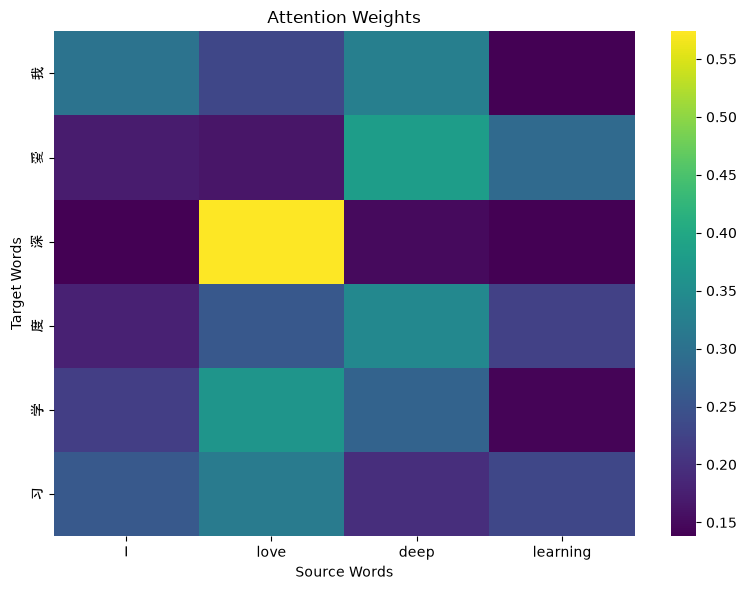

In [49]:
import subprocess
import platform
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import glob

# Colab/Linux 环境下安装中文字体，macOS/Windows 跳过
if platform.system() == 'Linux':
    subprocess.run(['apt-get', 'install', '-y', 'fonts-noto-cjk'], capture_output=True)

# 按优先级查找中文字体文件（兼容 Linux / macOS）
font_path = None
search_patterns = [
    '/usr/share/fonts/**/NotoSansCJK*.ttc',        # Linux (Noto CJK)
    '/usr/share/fonts/**/NotoSansCJK*.otf',         # Linux (Noto CJK otf)
    '/System/Library/Fonts/PingFang.ttc',           # macOS PingFang
    '/System/Library/Fonts/STHeiti*.ttc',            # macOS STHeiti
    '/System/Library/Fonts/Supplemental/Arial Unicode.ttf',  # macOS Arial Unicode
]
for pattern in search_patterns:
    candidates = glob.glob(pattern, recursive=True)
    if candidates:
        font_path = candidates[0]
        break

if font_path:
    print(f"使用字体: {font_path}")
    font_prop = fm.FontProperties(fname=font_path)
else:
    font_prop = None
    print("未找到中文字体，中文可能显示为方块")


def plot_attention(sentence, translation, attention_weights):
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(attention_weights, cmap='viridis',
                xticklabels=sentence.split(),
                yticklabels=list(translation), ax=ax)
    # 直接给 Y 轴标签设置字体，绕过 rcParams 字体名解析
    if font_prop:
        for label in ax.get_yticklabels():
            label.set_fontproperties(font_prop)
    plt.xlabel('Source Words')
    plt.ylabel('Target Words')
    plt.title('Attention Weights')
    plt.tight_layout()
    plt.savefig("attention_weights.jpg", dpi=150, bbox_inches="tight")
    plt.show()


# 获取 Attention Map 并绘图
model.eval()
src_text = "I love deep learning"
src_indices = torch.tensor([src_vocab[w] for w in src_text.split()]).unsqueeze(0).to(device)
src_mask = make_pad_mask(src_indices, src_indices, 0)

enc_out = model.encode(src_indices, src_mask)

tgt_indices = torch.tensor([[
    tgt_vocab['<sos>'],
    tgt_vocab['我'], tgt_vocab['爱'],
    tgt_vocab['深'], tgt_vocab['度'],
    tgt_vocab['学'], tgt_vocab['习']
]]).to(device)
tgt_mask = make_subsequent_mask(tgt_indices.size(1)).to(device)

output, attn_weights = model._decoder(model.tgt_embedding(tgt_indices), enc_out, src_mask, tgt_mask)

# 取第一个样本，平均所有头的注意力
attn_avg = attn_weights[0].mean(dim=0).detach().cpu().numpy()
plot_attention(src_text, "我爱深度学习", attn_avg[1:])

---

## 5.5 结语

至此，你已经从零开始构建并训练了一个 Transformer 模型，并完成了一次翻译任务。虽然这个模型很小，数据集也很小，但**原理和 ChatGPT、Claude 模型一样**。你把模型放大，数据放大，训练时间变长，就会得到一个非常强大的模型。用一首现代诗结尾（作者负责输出诗词大意，Claude 老师负责编写）：

> Embedding 把世界万物编织成向量，
> 让语言有了形状，让含义有了方向。
>
> Attention 在向量的海洋中捕捞关联，
> 让每个词回望全文，找到自己的锚点。
>
> Training 让模型一次次预测下一个 Token，
> 在错误与修正之间，逼近语言的本能。
>
> Loss 是黑暗中唯一的灯塔，
> 梯度沿着它的方向，一步步下山。
>
> Scaling 是一个朴素的信仰，
> 参数再多一些，数据再大一些，智能就涌现了。
>
> 模型终于开口，一个 Token 接一个 Token，
> 像孩子学会造句。
>
> 我们用矩阵乘法搭建了一座巴别塔，
> 它不通天，但它开始成为阶梯。

---

## 扩展思考 & 课后作业

### 思考题

<details>
<summary><b>📖 如果让你基于文章的代码，将模型改造为一个简单的 GPT 式 Causal Language Model（纯 Decoder，自回归生成），你需要做哪些修改？</b></summary>

1. **去掉 Encoder 和 Cross-Attention**
    - 只保留 Decoder，去掉所有 Cross-Attention 层
    - Self-Attention 使用 Causal Mask（下三角矩阵）
    - 原因：GPT 只需要"回看过去"，不需要源序列

2. **统一输入输出词表**
    - 不再区分 `src_vocab` 和 `tgt_vocab`
    - 使用同一个 tokenizer（如 BPE/SentencePiece）
    - 原因：LM 的输入和输出在同一个空间

3. **修改训练目标**
    - 输入：`tokens[:-1]`，标签：`tokens[1:]`
    - 每个位置都参与 loss 计算（不只是 Decoder 端）
    - 原因：Causal LM 的目标是预测序列中每个位置的下一个 token

4. **修改推理逻辑**
    - 给定 prompt，自回归生成续写
    - 不再需要 Encoder memory
    - 添加 KV Cache 提高推理速度

5. **（可选）架构微调**
    - Post-LN → Pre-LN（训练更稳定）
    - 添加 RoPE 位置编码（更好的长度外推）
    - ReLU → SwiGLU（更好的表达能力）

</details>

<details>
<summary><b>📖 Scaling Law 的核心观点是什么？有哪些局限性？</b></summary>

**核心观点**：模型性能与参数量 N、数据量 D、计算量 C 呈幂律关系，增加任一因素都能可预测地降低 Loss。**关键证据**：GPT 系列的持续改进；涌现能力（超过阈值后某些能力突然出现）。

**可能的局限**：

- **数据墙**：高质量文本数据有限，合成数据效果存疑
- **收益递减**：幂律意味着改进越来越难
- **能力不均衡**：数学/推理的 Scaling 效率远低于语言能力
- **涌现争议**：可能是度量选择的假象
- **成本与可持续性**：训练成本呈超线性增长

Scaling Law 可能是"必要但不充分"的——规模是基础，但架构创新（MoE、Mamba）和训练策略创新（RLHF、推理时计算 Scaling）可能带来更高效的提升。

</details>

### 课后作业

1. 去 Kaggle 或开源数据集下载一些中英、中日或你喜欢的数据集，把模型扩大，看下能不能训练一个自己的翻译模型。
2. 将模型改为 Decoder-Only 的模型，使用数据集训练下，看下模型会吐出什么结果。

---

## 全系列回顾

1. [第一篇：环境与前期准备](#part1) — 张量操作、nn.Module、常用层
2. [第二篇：数据处理与 Transformer 输入层](#part2) — 词表、Padding、Embedding、位置编码
3. [第三篇：多头注意力机制与核心组件](#part3) — 注意力、FFN、残差连接、Encoder/Decoder Layer
4. [第四篇：Transformer 模型组装](#part4) — Mask、Encoder、Decoder、完整 Transformer
5. [第五篇：训练、推理与可视化](#part5) — 损失函数、训练循环、推理、注意力可视化

### 参考文章

- [The Illustrated GPT-2](https://jalammar.github.io/illustrated-gpt2/) — Jay Alammar
- [保姆级教程：Transformer 本质是什么](https://zhuanlan.zhihu.com/p/692407578)
- [Transformer 模型详解（图解最完整版）](https://zhuanlan.zhihu.com/p/338817680)
- [三万字最全解析！从零实现 Transformer](https://zhuanlan.zhihu.com/p/648127076)
- [解剖注意力：从零构建 Transformer 的终极指南](https://zhuanlan.zhihu.com/p/1984265632687087772)
- [The Illustrated Transformer](https://jalammar.github.io/illustrated-transformer/) — Jay Alammar
- [The Transformer Family Version 2.0](https://lilianweng.github.io/posts/2023-01-27-the-transformer-family-v2/) — Lilian Weng
- [Attention? Attention!](https://lilianweng.github.io/posts/2018-06-24-attention/) — Lilian Weng
- [Transformers from scratch](https://peterbloem.nl/blog/transformers) — Peter Bloem

---

## 小彩蛋

安利一些好玩可交互网站：

**OpenAI Tokenizer 可视化**——自由输入文本，看在 OpenAI 中是哪个 token，还能看到 tokenId。果然"宋"是小姓，竟然才排到 99782，人家"王"是 15881。

![OpenAI Tokenizer](docs/images/05/1.png)

**Transformer Explainer**——强烈安利！这个网站允许你点击 generate 看下一个 token 是怎么通过前面的所有 token 在 Transformer 中计算出来的，非常直观，能显著提升你对 Transformer 的视觉理解水平！

![Transformer Explainer](docs/images/05/2.png)

**KV Cache Visualizer**——可视化交互 KV Cache 的网站。

![KV Cache Visualizer](docs/images/05/3.png)